# 4a — Hazard Maps: Current Exposure, Costa Rica

## Purpose
Build the current-conditions hazard-exposure layer for the Costa Rican main road network.
Each hazard raster is clipped to Costa Rica, mapped, and sampled onto every directed edge of
the network produced in `1b_Network_Preparation_CR`. The result is one table with a column per
hazard, saved as a GeoPackage for use in step 5.

The hazards are declared in a **registry** (section 5). Adding a hazard means appending one
`HazardLayer(...)` entry — no other cell changes.

## Inputs
| File | Description |
|------|-------------|
| `intermediate_results/gpkg/network/main_network_directed.gpkg` | Directed road network from 1b (EPSG:8908, 9,764 edges) |
| `input_files/ids_2023_distrital/ids_2023_distrito.shp` | IDS 2023 districts — dissolved to the Costa Rica outline |
| `input_files/flood_hazard_jrc/jrc_flood_cr_RP100_depth.tif` | JRC fluvial flood depth, 100-year return period (m, EPSG:4326, ~90 m) |
| `input_files/landslide_susceptibility/nasa_lhasa_susceptibility_cr.tif` | NASA LHASA landslide susceptibility, classes 0–5 (EPSG:4326, ~925 m) |
| `input_files/chirps_cr_anual/cr_chirps_anual_{2000..2025}.tif` | CHIRPS v2.0 annual precipitation totals (mm/yr, EPSG:4326, ~5.5 km) |
| `input_files/chirps_cr_mensual/cr_chirps_{YYYY}_{MM}.tif` | CHIRPS v2.0 monthly totals — the source of Rx1month (annual maximum monthly total) |

## Outputs
| File | Description |
|------|-------------|
| `intermediate_results/gpkg/hazard_exposure/main_network_hazard_exposure.gpkg` | Network with one value + one class column per hazard |
| `intermediate_results/gpkg/hazard_exposure/chirps_precip_anomaly_2025.tif` | Derived CHIRPS 2025 anomaly grid (z-score), so step 5 need not recompute it |
| `intermediate_results/gpkg/hazard_exposure/chirps_rx1month_rl20.tif` | Rx1month 20-year return level (GEV by L-moments) |
| `intermediate_results/gpkg/hazard_exposure/chirps_rx1month_trend.tif` | Rx1month Theil–Sen slope, mm/decade — descriptive, unmasked |
| `figures/chirps_rx1month_trend_descriptive.png` | Slope map with the field-significance null distribution |
| `figures/hazard_raster_{key}.png` | Each hazard raster over the Costa Rica outline |
| `figures/hazard_roads_{key}.png` | Roads coloured by hazard class |
| `figures/hazard_exposure_summary.png` | Share of network length exposed, by hazard |
| `figures/chirps_anomaly_panel.png` | Annual precipitation anomaly, four selected years |
| `figures/chirps_serie_temporal.png` | National mean annual precipitation, 2000–2025 |

## Key processing steps
1. **Base layers** — dissolve the IDS districts to a Costa Rica outline; load the directed network.
2. **Derived CHIRPS layer** — stack the annual totals, build the 2000–2024 climatology and
   its standard deviation, and express 2025 as an anomaly (mm) and a z-score (σ).
3. **Rx1month magnitude and trend** — take the annual maximum monthly total for every complete
   year, fit a GEV by L-moments for the 20-year return level, and estimate the Theil–Sen slope
   with Mann–Kendall significance under Benjamini–Hochberg FDR control.
4. **Hazard registry** — declare each hazard: source, units, road-reduction statistic, class
   breaks, colour map, and the threshold above which a road counts as exposed.
5. **Sampling** — densify each road to half the raster resolution, look up every vertex, and
   reduce per road with the layer's statistic. Vectorised over the whole network.
6. **Mapping and saving** — one raster map and one road map per hazard, an exposure summary,
   and a single GeoPackage carrying all hazard columns.

## Assumptions recorded in this notebook
- Costa Rica has **no national outline shapefile** in `input_files/`; the outline is the dissolved
  IDS 2023 district layer, which is authoritative for the districts but follows their generalised
  coastline. It includes the **Isla del Coco** district, 400 km offshore and roadless; maps are
  framed on the road network so the island does not dominate the extent.
- Rasters are kept in their **native EPSG:4326** and roads are reprojected to sample; maps are
  drawn in degrees. Only the saved network stays in **EPSG:8908**.
- Roads are reduced with **`max`** along the line (worst point governs), matching the convention
  used for flood depth in the Serbia pipeline. Set `stat="mean"` per layer to change this.
- The precipitation hazard is the **2025 anomaly against the 2000–2024 climatology**, as
  specified. Note this is one observed year, not a return-period hazard like the flood layer —
  a wet or dry 2025 is a description of that year, not a probability of recurrence. It is
  reported alongside the others but should not be read as an equivalent hazard intensity.
- CHIRPS pixels are ~5.5 km, so many roads in the same area receive the same anomaly value.
- **Rx1month is a substitute for Rx1day.** The index that actually drives washouts and landslide
  triggering is the annual maximum *daily* total; only monthly CHIRPS is available locally, so the
  wettest month stands in for it. A wet month of many moderate days and a wet month containing one
  extreme day score identically here and are not the same hazard.
- The monthly rasters contain `-9999` fill but **declare no nodata**, unlike the annual ones; they
  are masked explicitly in `read_monthly`.
- Only calendar-complete years enter the Rx1month series, so the partial year 2026 is excluded.
- The Rx1month statistics use **Costa Rican pixels only** (1,680 of the 2,432 land cells in the
  CHIRPS bounding box). Leaving the Nicaraguan and Panamanian cells in would inflate the number
  of tests entering the field-significance test.
- **The Rx1month trend is not a hazard layer, because it is not significant.** No pixel survives
  Benjamini–Hochberg correction at q = 0.05 or 0.10 (the best pixel reaches p = 6.5e-4 against a
  required threshold), and a permutation test that preserves the spatial correlation of the
  field lands on the 0.05 boundary. Twenty-six years is too short to demonstrate a trend in
  Costa Rican extreme-month rainfall. The slope map is produced for description only and `TREND_AS_HAZARD`
  is `False`; the pattern is suggestive of wetting but must not be reported as established.


## 1. Imports and configuration


In [7]:
# Standard library
from dataclasses import dataclass, field
from pathlib import Path
from typing import Callable
import re
import warnings

# Third-party
import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio
import shapely
from pyproj import Transformer
from rasterio.features import geometry_mask
from rasterio.transform import Affine
from scipy.spatial import cKDTree

# Matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap, TwoSlopeNorm
from matplotlib.patches import Patch
from mpl_toolkits.axes_grid1 import make_axes_locatable

warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=RuntimeWarning)

In [8]:
# ---- Paths -------------------------------------------------------------
BASE_DIR = Path.cwd().parent          # notebook lives in /notebooks
data_path = BASE_DIR / "input_files"
figure_path = BASE_DIR / "figures"
intermediate_path = BASE_DIR / "intermediate_results"

# Shared CR map style: extent, basemap, outline, cities, legend (src/map_style_cr.py)
import sys
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))
from src.map_style_cr import add_cr_legend, style_cr_map

network_gpkg = intermediate_path / "gpkg" / "network" / "main_network_directed.gpkg"
districts_shp = data_path / "ids_2023_distrital" / "ids_2023_distrito.shp"

flood_tif = data_path / "flood_hazard_jrc" / "jrc_flood_cr_RP100_depth.tif"
flood_rp_dir = data_path / "flood_hazard_jrc"
landslide_tif = data_path / "landslide_susceptibility" / "nasa_lhasa_susceptibility_cr.tif"
chirps_dir = data_path / "chirps_cr_anual"
chirps_monthly_dir = data_path / "chirps_cr_mensual"
structures_shp = data_path / "CR_RVN_ESTRUCTURAS_V2" / "cr_rvn_estructuras_v2.shp"
dem_dir = data_path / "dem"           # optional — see the DEM / road-Z gate (section 7b)

hazard_out_dir = intermediate_path / "gpkg" / "hazard_exposure"
hazard_gpkg = hazard_out_dir / "main_network_hazard_exposure.gpkg"

hazard_out_dir.mkdir(parents=True, exist_ok=True)
figure_path.mkdir(parents=True, exist_ok=True)

# ---- Constants ---------------------------------------------------------
WORKING_EPSG = 8908           # CR-SIRGAS / CRTM05, metres — the CRS of every saved vector
RASTER_EPSG = 4326            # all hazard rasters are geographic; maps are drawn in degrees
DPI = 300

# CHIRPS anomaly definition
CLIM_START, CLIM_END = 2000, 2024      # climatology window, inclusive
ANOMALY_YEAR = 2025                    # the year expressed as an anomaly
PANEL_YEARS = [2022, 2023, 2024, 2025] # years shown in the anomaly panel

# Rx1month magnitude and trend
RETURN_PERIOD = 20.0          # years; a 26-year record cannot support 100
FDR_ALPHA = 0.05              # Benjamini-Hochberg false-discovery rate for the trend
# The field test lands near p = 0.05, so the permutation count has to be large enough to
# resolve which side of it we are on: at 1,000 the standard error on p is ~0.007.
N_PERMUTATIONS = 1000         # permutations for the field-significance test (~4 min)
# The 2000-2025 record does not support a per-pixel Rx1month trend (see section 5), so the
# trend is reported as a descriptive map only. Set True to also enter it in HAZARDS.
TREND_AS_HAZARD = False

# ---- Flood configuration -------------------------------------------------
# Decisions D2 / D5 / D6 of MD/5a_Main_Network_Hazard_Criticality_CR_plan.md.

# D2 — a road counts as flood-exposed when its DEEPEST sampled point exceeds this.
# Inherited from the Serbia pipeline for continuity. It is not derived here and has
# no stated justification in either pipeline (plan issue I6): treat it as a
# convention, not a trafficability finding.
FLOOD_DEPTH_THRESHOLD = 0.25          # m

# All seven JRC grids share one footprint (3841 x 4201, ~93 m), so the same rule can
# be applied across return periods to get an exceedance frequency (section 7a).
RETURN_PERIODS = [10, 20, 50, 75, 100, 200, 500]      # years

# D5 — bridge decks sit above the design flood, so flood cells within this distance of
# a mapped water-crossing structure are excluded before the depth is reduced.
# ASSUMPTION (plan issues I1b / I8): 50 m is the scale of a deck plus its approaches.
# It is NOT calibrated. Section 7c reports the effect at 25 / 50 / 100 m so the size of
# the choice stays visible.
BRIDGE_MASK_M = 50.0                  # m
WATER_CROSSINGS = ["RIO", "QUEBRADA", "CANAL", "ESTERO"]
# Temporary or low-capacity structure types, flagged separately as a vulnerability.
FRAGILE_STRUCTURE_PATTERN = "Bailey|Alcantarilla"

# I2 — depths above this are river cross-sections, not road inundation. Roads are
# FLAGGED, never clipped, so the raw value stays inspectable.
# ASSUMPTION: 6 m. JRC RP100 floodplain depths away from channels rarely exceed this;
# the observed CR maximum is 30.7 m, which is unambiguously a channel.
FLOOD_DEPTH_CEILING = 6.0             # m

print(f"Base dir      : {BASE_DIR}")
print(f"Network       : {network_gpkg.name}  (exists: {network_gpkg.exists()})")
print(f"Hazard output : {hazard_gpkg.relative_to(BASE_DIR)}")

Base dir      : /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR
Network       : main_network_directed.gpkg  (exists: True)
Hazard output : intermediate_results/gpkg/hazard_exposure/main_network_hazard_exposure.gpkg


## 2. Raster container and generic helpers

`Raster` holds a hazard grid together with everything needed to map it and to look values up.
Every hazard — read from a file or computed in this notebook — is turned into one of these, so
the sampling and plotting code below never needs to know where a layer came from.


In [9]:
@dataclass
class Raster:
    """A hazard grid in a known CRS, with nodata already converted to NaN."""

    data: np.ndarray
    transform: Affine
    crs: str

    @property
    def extent(self) -> tuple[float, float, float, float]:
        """(left, right, bottom, top) for matplotlib imshow with origin='upper'."""
        h, w = self.data.shape
        left, top = self.transform * (0, 0)
        right, bottom = self.transform * (w, h)
        return (left, right, bottom, top)

    @property
    def resolution(self) -> float:
        return min(abs(self.transform.a), abs(self.transform.e))


def read_raster(path: Path) -> Raster:
    """Read a single-band GeoTIFF, converting nodata to NaN."""
    with rasterio.open(path) as src:
        data = src.read(1).astype("float64")
        if src.nodata is not None:
            data = np.where(data == src.nodata, np.nan, data)
        return Raster(data=data, transform=src.transform, crs=str(src.crs))


def clip_to_outline(raster: Raster, outline: gpd.GeoDataFrame) -> Raster:
    """Blank out cells whose centre falls outside *outline* (reprojected to the raster CRS)."""
    shapes = outline.to_crs(raster.crs).geometry.values
    inside = geometry_mask(
        shapes, transform=raster.transform, invert=True, out_shape=raster.data.shape
    )
    return Raster(
        data=np.where(inside, raster.data, np.nan),
        transform=raster.transform,
        crs=raster.crs,
    )


def write_raster(raster: Raster, path: Path) -> None:
    """Save a derived grid so downstream steps do not have to recompute it."""
    h, w = raster.data.shape
    with rasterio.open(
        path, "w", driver="GTiff", height=h, width=w, count=1,
        dtype="float32", crs=raster.crs, transform=raster.transform, nodata=-9999.0,
    ) as dst:
        dst.write(np.nan_to_num(raster.data, nan=-9999.0).astype("float32"), 1)


def save_fig(fig, filename: str, dpi: int = DPI) -> None:
    out = figure_path / filename
    fig.savefig(out, dpi=dpi, bbox_inches="tight")
    print(f"saved  {out.relative_to(BASE_DIR)}")


## 3. Base layers — Costa Rica outline and the directed network


In [10]:
# Costa Rica outline: no national boundary file ships with input_files/, so the IDS 2023
# district layer is dissolved into a single polygon.
districts = gpd.read_file(districts_shp)
cr_outline = gpd.GeoDataFrame(
    geometry=[districts.union_all()], crs=districts.crs
)
cr_outline_deg = cr_outline.to_crs(RASTER_EPSG)

roads = gpd.read_file(network_gpkg)
roads_deg = roads.to_crs(RASTER_EPSG)

# The IDS layer includes the Isla del Coco district (~5.5 N, 87 W), which is 400 km
# offshore and carries no roads. cr_outline keeps it (it is the raster clip mask); the
# maps are framed on the mainland by style_cr_map (src/map_style_cr.py), which also adds
# the basemap, the outside fade, the national outline, the cities and the legend.
# Maps in this notebook are drawn in degrees (RASTER_EPSG), the CRS of the rasters.

print(f"Districts dissolved : {len(districts)} -> 1 outline  ({districts.crs})")
print(f"Network             : {len(roads)} directed edges, "
      f"{roads['physical_edge_id'].nunique()} physical roads  ({roads.crs})")
print(f"Total network length: {roads['road_length'].sum():,.0f} km")


Districts dissolved : 492 -> 1 outline  (EPSG:8908)
Network             : 9764 directed edges, 5012 physical roads  (EPSG:8908)
Total network length: 29,528 km


## 4. Derived layer — CHIRPS annual precipitation anomaly

The precipitation hazard is not a file on disk: it is built here from the annual CHIRPS totals.
The climatology is the **2000–2024** mean and standard deviation; 2025 is expressed both as an
absolute anomaly (mm) and as a z-score (σ), and the z-score is what the registry samples onto
the roads so that it is comparable across the country.


In [11]:
# ---- Load every available annual total -----------------------------------
annual: dict[int, Raster] = {}
for year in range(CLIM_START, ANOMALY_YEAR + 1):
    path = chirps_dir / f"cr_chirps_anual_{year}.tif"
    if path.exists():
        annual[year] = read_raster(path)

years_loaded = sorted(annual)
print(f"Years loaded: {years_loaded[0]}–{years_loaded[-1]} ({len(years_loaded)} files)")

missing = [y for y in range(CLIM_START, ANOMALY_YEAR + 1) if y not in annual]
if missing:
    print(f"WARNING missing years: {missing}")

# All CHIRPS grids share one footprint; take the first as the reference.
ref = annual[years_loaded[0]]
assert all(r.data.shape == ref.data.shape for r in annual.values()), \
    "CHIRPS grids differ in shape — regrid before stacking"

# ---- Climatology 2000–2024 -----------------------------------------------
clim_years = [y for y in range(CLIM_START, CLIM_END + 1) if y in annual]
stack = np.array([annual[y].data for y in clim_years])
climatology = np.nanmean(stack, axis=0)
sigma = np.nanstd(stack, axis=0)
sigma[sigma == 0] = np.nan

print(f"Climatology : {min(clim_years)}–{max(clim_years)} ({len(clim_years)} years)  |  "
      f"national mean {np.nanmean(climatology):,.0f} mm/yr")

# ---- Anomalies -----------------------------------------------------------
anomalies = {y: annual[y].data - climatology for y in years_loaded}
z_scores = {y: anomalies[y] / sigma for y in years_loaded}

precip_anomaly = Raster(z_scores[ANOMALY_YEAR], ref.transform, ref.crs)
precip_anomaly_mm = Raster(anomalies[ANOMALY_YEAR], ref.transform, ref.crs)

print(f"{ANOMALY_YEAR} anomaly : {np.nanmean(anomalies[ANOMALY_YEAR]):+,.0f} mm  "
      f"({np.nanmean(z_scores[ANOMALY_YEAR]):+.2f} σ national mean)")


Years loaded: 2000–2025 (26 files)
Climatology : 2000–2024 (25 years)  |  national mean 2,857 mm/yr
2025 anomaly : +376 mm  (+0.96 σ national mean)


saved  figures/chirps_anomaly_panel.png


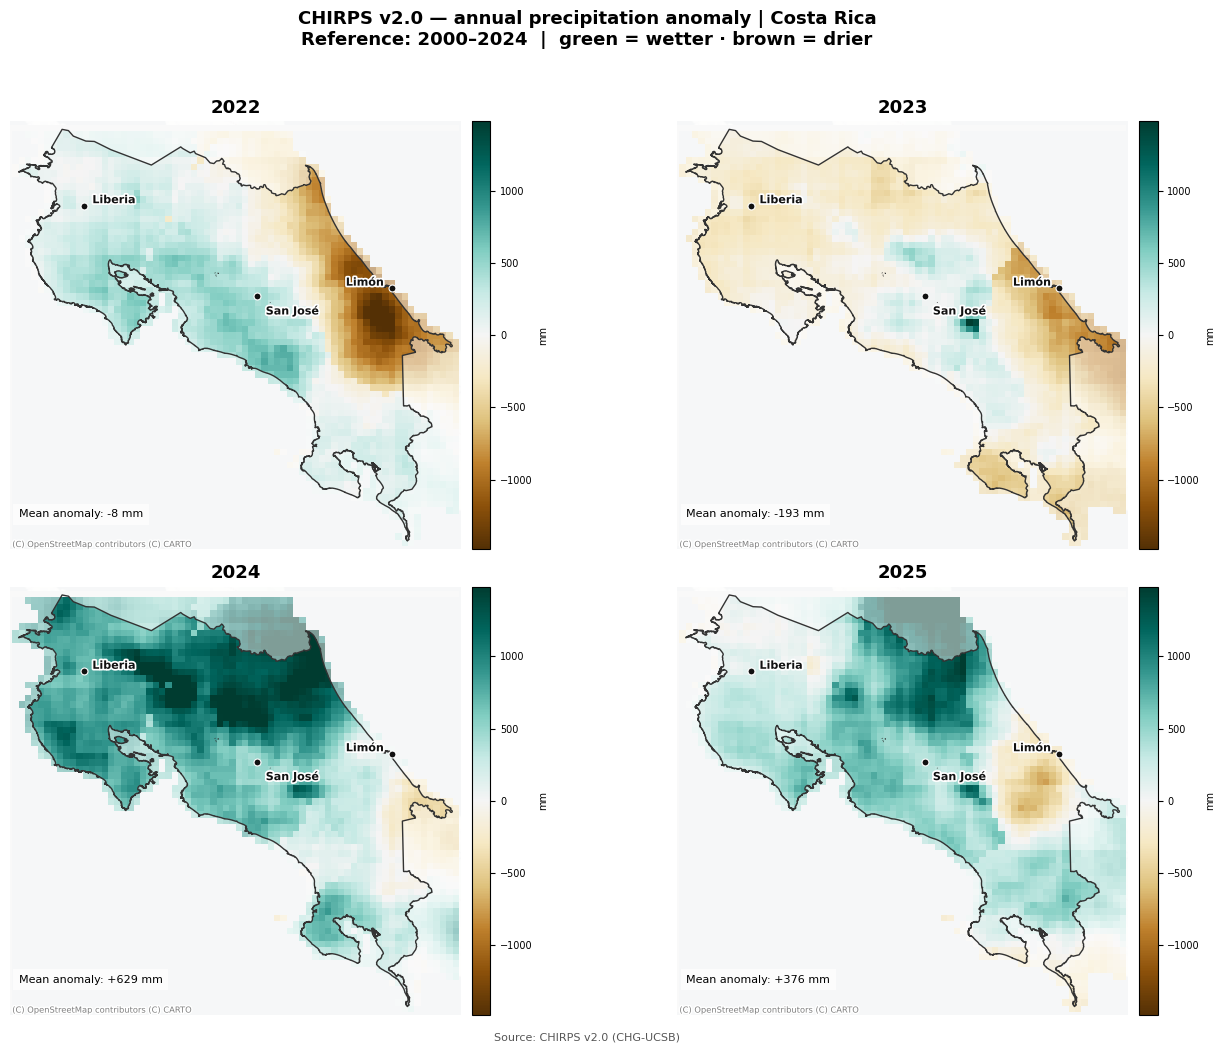

In [12]:
# ---- Panel of absolute anomalies for the selected years -------------------
panel = [y for y in PANEL_YEARS if y in anomalies]
finite = np.concatenate([anomalies[y][np.isfinite(anomalies[y])].ravel() for y in panel])
vlim = np.percentile(np.abs(finite), 98)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, year in zip(axes.ravel(), panel):
    arr = anomalies[year]
    norm = TwoSlopeNorm(vmin=-vlim, vcenter=0, vmax=vlim)
    im = ax.imshow(arr, extent=ref.extent, origin="upper", cmap="BrBG", norm=norm)
    style_cr_map(ax, RASTER_EPSG, city_fontsize=8)
    mean = np.nanmean(arr)
    ax.set_title(str(year), fontsize=13, fontweight="bold", pad=6)
    ax.text(0.02, 0.07, f"Mean anomaly: {mean:+,.0f} mm", transform=ax.transAxes,
            fontsize=8, va="bottom", zorder=30,   # above the outside-fade layer
            bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"))
    cax = make_axes_locatable(ax).append_axes("right", size="4%", pad=0.08)
    cb = plt.colorbar(im, cax=cax)
    cb.set_label("mm", fontsize=7)
    cb.ax.tick_params(labelsize=7)

for ax in axes.ravel()[len(panel):]:
    ax.axis("off")

fig.suptitle(
    "CHIRPS v2.0 — annual precipitation anomaly | Costa Rica\n"
    f"Reference: {min(clim_years)}–{max(clim_years)}  |  green = wetter · brown = drier",
    fontsize=13, fontweight="bold", y=1.02,
)
fig.text(0.5, -0.01, "Source: CHIRPS v2.0 (CHG-UCSB)", ha="center",
         fontsize=8, color="#555555")
plt.tight_layout()
save_fig(fig, "chirps_anomaly_panel.png")
plt.show()


saved  figures/chirps_serie_temporal.png


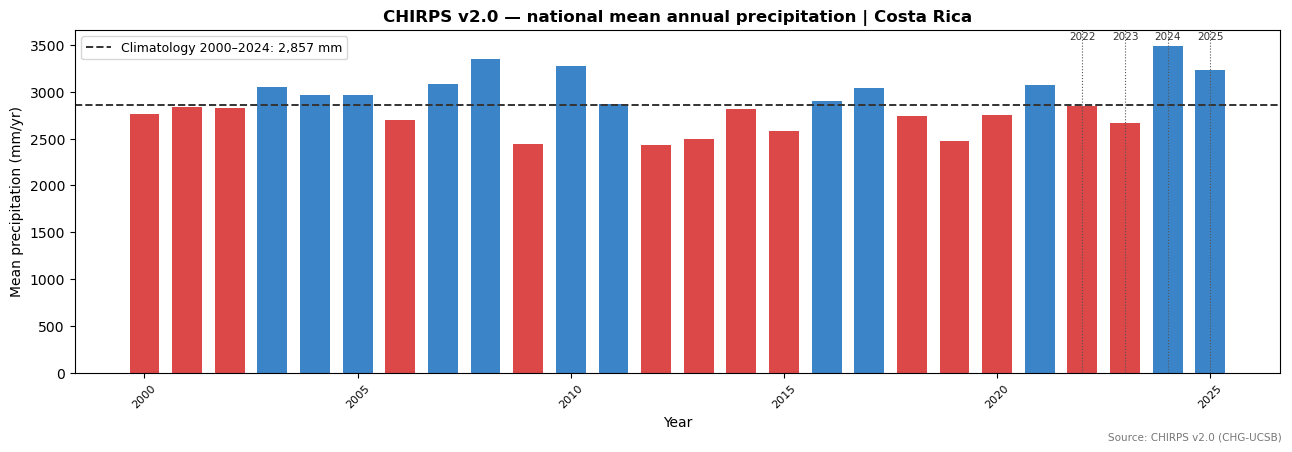

In [13]:
# ---- National mean time series -------------------------------------------
means = [np.nanmean(annual[y].data) for y in years_loaded]
clim_val = np.nanmean(climatology)
colors = ["#1a6fbf" if m >= clim_val else "#d62728" for m in means]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(years_loaded, means, color=colors, alpha=0.85, width=0.7)
ax.axhline(clim_val, color="#333333", linewidth=1.4, linestyle="--",
           label=f"Climatology {min(clim_years)}–{max(clim_years)}: {clim_val:,.0f} mm")
for year in panel:
    ax.axvline(year, color="#555555", linewidth=0.8, linestyle=":")
    ax.text(year, max(means) * 1.02, str(year), ha="center", fontsize=7.5, color="#333333")
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Mean precipitation (mm/yr)", fontsize=10)
ax.set_title("CHIRPS v2.0 — national mean annual precipitation | Costa Rica",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=9)
ax.tick_params(axis="x", rotation=45, labelsize=8)
fig.text(0.99, 0.01, "Source: CHIRPS v2.0 (CHG-UCSB)", ha="right",
         fontsize=7.5, color="#777777")
plt.tight_layout()
save_fig(fig, "chirps_serie_temporal.png")
plt.show()


## 5. Derived layers — Rx1month magnitude and trend

`Rx1month` is the wettest calendar month of each year. Twenty-six of them (2000–2025) give a
sample of annual maxima, from which two distinct things are derived:

- **Magnitude** — a GEV fitted to the 26 maxima, read at the 20-year return level. This is a
  *probability* statement ("the monthly total exceeded once in 20 years"), directly comparable
  to the flood layer's RP100, and unlike the 2025 anomaly it does not depend on which year
  happened to be sampled.
- **Trend** — the Theil–Sen slope in mm/decade, kept only where the Mann–Kendall test survives
  Benjamini–Hochberg FDR control. This is *change*, not intensity, and is deliberately a
  separate column rather than being folded into the magnitude.

### Why Rx1month and not Rx1day
The established index for rainfall-driven road hazard is **Rx1day** — the largest single-day
total of the year. It is what the Serbia pipeline used, and it is the better predictor of
washouts and landslide triggering, because those respond to short bursts of intense rain rather
than to a generally wet month. A 600 mm month made of thirty 20 mm days and a 600 mm month
containing one 250 mm day are the same Rx1month and very different hazards.

Rx1day cannot be computed here: `input_files/chirps_cr_mensual/` is monthly, and daily CHIRPS is
not in `input_files/`. Rx1month is the closest available substitute and is used on that basis.
Downloading daily CHIRPS (or CHG's pre-computed Rx1day) would let `rx1month_stack()` below be
swapped for a daily equivalent without any other change to this notebook.

### Estimator choices
- **L-moments, not maximum likelihood**, for the GEV fit: at n = 26 the MLE shape parameter is
  unstable, while L-moments stay well behaved on short records.
- **Theil–Sen and Mann–Kendall, not OLS**: both are non-parametric and robust to the ENSO-driven
  outlier years that dominate Costa Rican interannual variability.
- **20 years, not 100**: a 26-year record cannot support a 100-year return level. The rule of
  thumb is a return period no longer than roughly twice the record.
- **FDR control**: CHIRPS cells are ~5.5 km and strongly spatially correlated, so the effective
  number of independent tests is far below the ~2,400 pixels. Testing each at p < 0.05 would
  report a large area as significant by construction.


In [14]:
from scipy import stats
from scipy.special import gamma as gamma_fn

MONTHLY_FILL = -9990.0   # the monthly rasters carry -9999 but declare no nodata


def read_monthly(path: Path) -> np.ndarray:
    """Read a monthly CHIRPS total, masking the undeclared -9999 fill."""
    with rasterio.open(path) as src:
        data = src.read(1).astype("float64")
    return np.where(data <= MONTHLY_FILL, np.nan, data)


def rx1month_stack() -> tuple[np.ndarray, np.ndarray, Affine, str]:
    """Annual maxima of monthly totals: (stack[year, y, x], years, transform, crs).

    Only calendar-complete years are used, so a partly downloaded year cannot
    depress its own maximum.
    """
    by_year: dict[int, dict[int, Path]] = {}
    for path in sorted(chirps_monthly_dir.glob("cr_chirps_*_*.tif")):
        match = re.search(r"_(\d{4})_(\d{2})", path.name)
        if match:
            year, month = map(int, match.groups())
            by_year.setdefault(year, {})[month] = path

    complete = [y for y in sorted(by_year) if len(by_year[y]) == 12]
    partial = {y: len(v) for y, v in by_year.items() if len(v) != 12}
    if partial:
        print(f"excluded incomplete years: {partial}")

    stack = np.array(
        [np.nanmax(np.array([read_monthly(by_year[y][m]) for m in range(1, 13)]), axis=0)
         for y in complete]
    )
    with rasterio.open(by_year[complete[0]][1]) as src:
        transform, crs = src.transform, str(src.crs)
    return stack, np.array(complete, dtype=float), transform, crs


def gev_return_level(stack: np.ndarray, return_period: float) -> np.ndarray:
    """GEV return level per pixel, fitted by L-moments (Hosking & Wallis).

    Vectorised over pixels: the sample L-moments come from probability-weighted
    moments of the time-sorted stack.
    """
    n = stack.shape[0]
    ordered = np.sort(stack, axis=0)
    rank = np.arange(1, n + 1)[:, None, None]

    b0 = ordered.mean(axis=0)
    b1 = (((rank - 1) / (n - 1)) * ordered).sum(axis=0) / n
    b2 = (((rank - 1) * (rank - 2) / ((n - 1) * (n - 2))) * ordered).sum(axis=0) / n

    l1, l2, l3 = b0, 2 * b1 - b0, 6 * b2 - 6 * b1 + b0
    t3 = l3 / l2

    c = 2 / (3 + t3) - np.log(2) / np.log(3)
    shape = 7.8590 * c + 2.9554 * c**2
    scale = l2 * shape / ((1 - 2.0**-shape) * gamma_fn(1 + shape))
    loc = l1 - scale * (1 - gamma_fn(1 + shape)) / shape

    prob = 1 - 1 / return_period
    return loc + scale * (1 - (-np.log(prob)) ** shape) / shape


def theil_sen_trend(
    stack: np.ndarray, years: np.ndarray, fdr_alpha: float = 0.05
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Per-pixel slope (units/decade), raw Mann-Kendall p, and the FDR-significant mask."""
    slope = np.full(stack.shape[1:], np.nan)
    pval = np.full(stack.shape[1:], np.nan)

    complete = np.isfinite(stack).all(axis=0)
    rows, cols = np.where(complete)
    for i, j in zip(rows, cols):
        series = stack[:, i, j]
        slope[i, j] = stats.theilslopes(series, years)[0] * 10
        pval[i, j] = stats.kendalltau(years, series).pvalue

    # kendalltau returns NaN for a constant series, and false_discovery_control
    # rejects any non-finite p, so the correction runs over tested pixels only.
    testable = np.isfinite(pval)
    adjusted = stats.false_discovery_control(pval[testable], method="bh")
    significant = np.zeros(stack.shape[1:], dtype=bool)
    significant[testable] = adjusted < fdr_alpha
    return slope, pval, significant


def field_significance(
    stack: np.ndarray, years: np.ndarray, pval: np.ndarray,
    alpha: float = 0.05, n_permutations: int = N_PERMUTATIONS, seed: int = 0,
) -> tuple[int, np.ndarray, float]:
    """Is the *number* of locally significant pixels more than chance would give?

    Every pixel is permuted with the **same** shuffling of years, so the spatial
    correlation of the field is preserved under the null. Testing each pixel
    independently would otherwise treat ~2,300 strongly correlated cells as
    ~2,300 independent trials.
    """
    rng = np.random.default_rng(seed)
    testable = np.isfinite(pval)
    rows, cols = np.where(testable)
    observed = int((pval[testable] < alpha).sum())

    null = np.empty(n_permutations, dtype=int)
    for b in range(n_permutations):
        shuffled = years[rng.permutation(len(years))]
        null[b] = sum(
            stats.kendalltau(shuffled, stack[:, i, j]).pvalue < alpha
            for i, j in zip(rows, cols)
        )
    return observed, null, float((null >= observed).mean())


In [15]:
rx1month, rx_years, rx_transform, rx_crs = rx1month_stack()

# The CHIRPS extract covers a bounding box, so it carries land pixels in Nicaragua and
# Panama. Every statistic below — the GEV fit, the trend, and above all the count of
# pixels entering the field-significance test — must be Costa Rica only.
_cr_cells = geometry_mask(
    cr_outline.to_crs(rx_crs).geometry.values,
    transform=rx_transform, invert=True, out_shape=rx1month.shape[1:],
)
_before = int(np.isfinite(rx1month[0]).sum())
rx1month = np.where(_cr_cells, rx1month, np.nan)
_after = int(np.isfinite(rx1month[0]).sum())

print(f"Rx1month: {int(rx_years[0])}–{int(rx_years[-1])} ({len(rx_years)} complete years), "
      f"national mean {np.nanmean(rx1month):,.0f} mm/month")
print(f"          clipped to Costa Rica: {_before:,} -> {_after:,} pixels")

# --- Magnitude: 20-year return level -------------------------------------
rl20 = gev_return_level(rx1month, RETURN_PERIOD)
precip_rl = Raster(rl20, rx_transform, rx_crs)
finite_rl = rl20[np.isfinite(rl20)]
print(f"RL{RETURN_PERIOD:.0f}: median {np.median(finite_rl):,.0f} mm  "
      f"(p10 {np.percentile(finite_rl, 10):,.0f} – p90 {np.percentile(finite_rl, 90):,.0f})")

# --- Trend: Theil-Sen slope, FDR-masked ----------------------------------
slope, pval, significant = theil_sen_trend(rx1month, rx_years, fdr_alpha=FDR_ALPHA)
tested = np.isfinite(slope)
naive = tested & (pval < 0.05)
print(f"Trend: median {np.nanmedian(slope[tested]):+.1f} mm/decade over {tested.sum():,} pixels")
print(f"       p<0.05 uncorrected : {naive.sum():,} ({naive.sum() / tested.sum():.1%}) "
      f"| {(naive & (slope > 0)).sum():,} increasing, {(naive & (slope < 0)).sum():,} decreasing")
print(f"       BH-FDR q<{FDR_ALPHA}      : {significant.sum():,} "
      f"({significant.sum() / tested.sum():.1%}) — these are the pixels the layer keeps")

# Pixels without a detected trend stay NaN: 'no trend detected', not 'zero trend'.
precip_trend = Raster(np.where(significant, slope, np.nan), rx_transform, rx_crs)
precip_trend_raw = Raster(slope, rx_transform, rx_crs)   # descriptive, unmasked


excluded incomplete years: {2026: 7}
Rx1month: 2000–2025 (26 complete years), national mean 559 mm/month
          clipped to Costa Rica: 2,432 -> 1,680 pixels
RL20: median 749 mm  (p10 571 – p90 1,008)
Trend: median +27.3 mm/decade over 1,680 pixels
       p<0.05 uncorrected : 263 (15.7%) | 249 increasing, 14 decreasing
       BH-FDR q<0.05      : 0 (0.0%) — these are the pixels the layer keeps


In [16]:
# --- Is the field as a whole trending, even if no single pixel is? ---------
observed, null, field_p = field_significance(rx1month, rx_years, pval, alpha=0.05)
print(f"Field significance ({N_PERMUTATIONS} permutations, spatial structure preserved)")
print(f"  observed pixels with p<0.05 : {observed:,} ({observed / np.isfinite(pval).sum():.1%})")
print(f"  null mean {null.mean():.0f}  |  null p95 {np.percentile(null, 95):.0f}  |  "
      f"null max {null.max()}")
field_se = float(np.sqrt(field_p * (1 - field_p) / N_PERMUTATIONS))
print(f"  field p-value = {field_p:.3f}  (+/- {1.96 * field_se:.3f} at 95% from "
      f"{N_PERMUTATIONS} permutations)")
print()

# The verdict is derived, not asserted: pixel-level and field-level evidence answer
# different questions and a short record lets them disagree.
n_tested = int(np.isfinite(pval).sum())
print("VERDICT")
if significant.sum() > 0:
    print(f"  Pixel level : {significant.sum():,} pixels survive FDR q<{FDR_ALPHA}.")
else:
    print(f"  Pixel level : no pixel survives FDR q<{FDR_ALPHA} "
          f"(best p = {np.nanmin(pval):.1e}, needed <= {FDR_ALPHA / n_tested:.1e}).")
if field_p > 0.05 + 1.96 * field_se:
    print(f"  Field level : not significant (p = {field_p:.3f}).")
elif field_p < 0.05 - 1.96 * field_se:
    print(f"  Field level : significant (p = {field_p:.3f}) — more pixels trend than chance")
    print("                allows, though no individual pixel can be pointed to.")
else:
    print(f"  Field level : borderline (p = {field_p:.3f}, indistinguishable from 0.05 at")
    print(f"                {N_PERMUTATIONS} permutations).")
print()
print(f"  => TREND_AS_HAZARD = {TREND_AS_HAZARD}. The slope map below is descriptive. The")
print("     direction is consistently wetting, but 26 years cannot establish it per pixel.")


Field significance (1000 permutations, spatial structure preserved)
  observed pixels with p<0.05 : 263 (15.7%)
  null mean 76  |  null p95 253  |  null max 919
  field p-value = 0.044  (+/- 0.013 at 95% from 1000 permutations)

VERDICT
  Pixel level : no pixel survives FDR q<0.05 (best p = 6.5e-04, needed <= 3.0e-05).
  Field level : borderline (p = 0.044, indistinguishable from 0.05 at
                1000 permutations).

  => TREND_AS_HAZARD = False. The slope map below is descriptive. The
     direction is consistently wetting, but 26 years cannot establish it per pixel.


saved  figures/chirps_rx1month_trend_descriptive.png


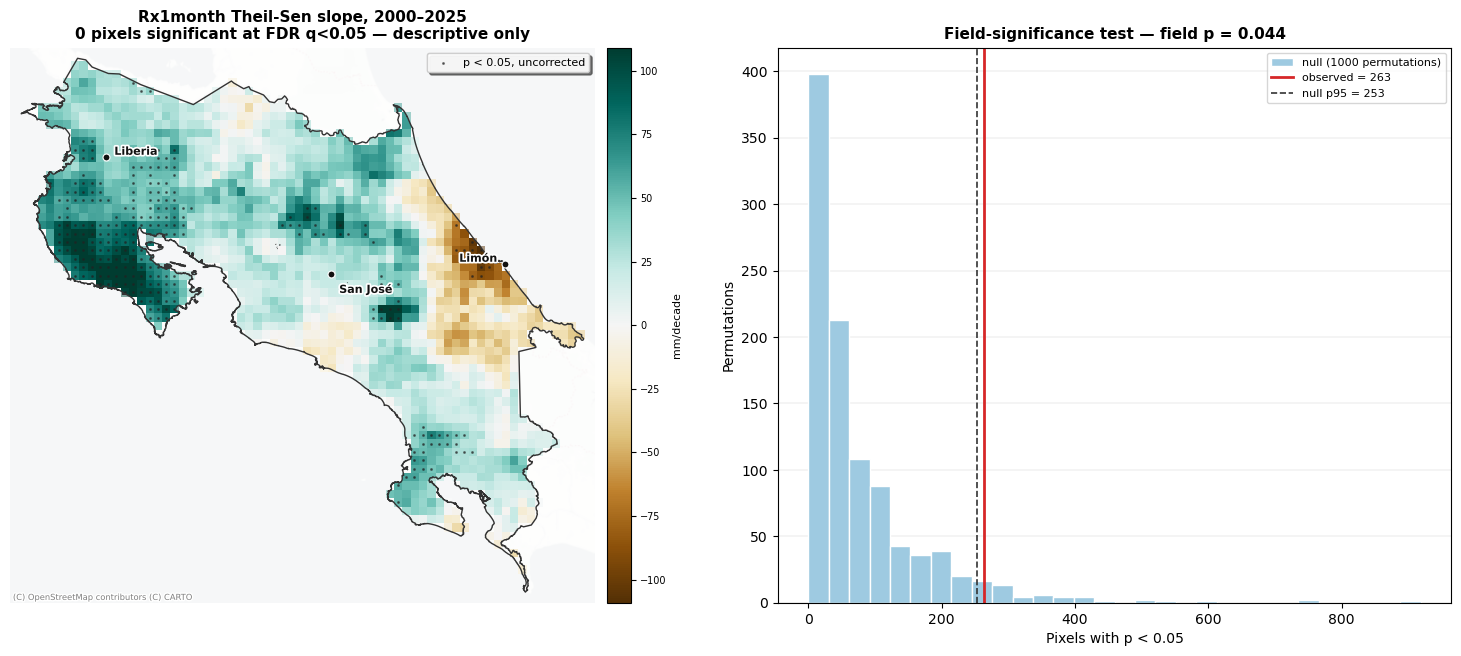

In [17]:
# --- Descriptive map of the slope, explicitly labelled as not significant ---
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

vlim = np.nanpercentile(np.abs(slope), 98)
im = axes[0].imshow(slope, extent=precip_trend_raw.extent, origin="upper",
                    cmap="BrBG", norm=TwoSlopeNorm(vmin=-vlim, vcenter=0, vmax=vlim))
# Stipple the pixels that would pass an uncorrected test, to show what correction removes.
naive_rows, naive_cols = np.where(np.isfinite(pval) & (pval < 0.05))
xs, ys = precip_trend_raw.transform * (naive_cols + 0.5, naive_rows + 0.5)
axes[0].scatter(xs, ys, s=1.2, color="#222222", alpha=0.55, zorder=6,
                label="p < 0.05, uncorrected")
style_cr_map(axes[0], RASTER_EPSG,
             legend_handles=axes[0].get_legend_handles_labels()[0],
             legend_kw=dict(fontsize=8, title_fontsize=9), city_fontsize=8)
axes[0].set_title(f"Rx1month Theil-Sen slope, {int(rx_years[0])}–{int(rx_years[-1])}\n"
                  f"{significant.sum()} pixels significant at FDR q<{FDR_ALPHA} "
                  f"— descriptive only",
                  fontsize=11, fontweight="bold")
cax = make_axes_locatable(axes[0]).append_axes("right", size="4%", pad=0.08)
cb = plt.colorbar(im, cax=cax)
cb.set_label("mm/decade", fontsize=8)
cb.ax.tick_params(labelsize=7)

axes[1].hist(null, bins=30, color="#9ecae1", edgecolor="white",
             label=f"null ({N_PERMUTATIONS} permutations)")
axes[1].axvline(observed, color="#d62728", linewidth=2,
                label=f"observed = {observed:,}")
axes[1].axvline(np.percentile(null, 95), color="#333333", linestyle="--", linewidth=1.2,
                label=f"null p95 = {np.percentile(null, 95):.0f}")
axes[1].set_xlabel("Pixels with p < 0.05", fontsize=10)
axes[1].set_ylabel("Permutations", fontsize=10)
axes[1].set_title(f"Field-significance test — field p = {field_p:.3f}",
                  fontsize=11, fontweight="bold")
axes[1].legend(fontsize=8)
axes[1].grid(axis="y", linewidth=0.3, color="#cccccc")
axes[1].set_axisbelow(True)

plt.tight_layout()
save_fig(fig, "chirps_rx1month_trend_descriptive.png")
plt.show()


## 5b. Road structures at water crossings

`CR_RVN_ESTRUCTURAS_V2` maps 1,962 structures on the national network. They enter the analysis
**twice, in opposite roles**, and the two must never be conflated (plan decision D5):

- as a **vulnerability** — a road that depends on N bridges over rivers has N single points of
  failure, and the temporary/low-capacity stock (`Bailey`, `Alcantarilla`) is the fragile end of it;
- as a **protection** — a bridge deck sits *above* the design flood, so the JRC depth sampled at a
  crossing describes the river, not the road surface. Those cells are masked out before the flood
  depth is reduced.

Both are computed here. The vulnerability columns are `n_water_crossings` and
`has_temporary_structure`; the protection is applied inside the flood layer and reported as a
before/after pair in section 7c.

In [18]:
# ---- Structures: water crossings -----------------------------------------
structures = gpd.read_file(structures_shp).to_crs(WORKING_EPSG)
water = structures[structures["CRUZ_SOBR"].isin(WATER_CROSSINGS)].copy()
water["fragile"] = water["TIP_ESTR"].str.contains(
    FRAGILE_STRUCTURE_PATTERN, na=False, regex=True
)

# Coordinates used to mask flood cells on bridge decks (the "protection" role).
bridge_mask_xy = np.column_stack([water.geometry.x.to_numpy(), water.geometry.y.to_numpy()])

# Per-road counts (the "vulnerability" role). Structures are snapped to the nearest
# PHYSICAL road, not to a directed edge: the two directed edges of one road share a
# geometry, so joining to them would assign each structure arbitrarily to one of the pair.
# ASSUMPTION: the same 50 m used for the mask is the snap tolerance; a structure further
# than that from any road is not attributed.
physical = roads.drop_duplicates("physical_edge_id")[["physical_edge_id", "geometry"]]
joined = gpd.sjoin_nearest(
    water[["fragile", "geometry"]], physical, how="inner", max_distance=BRIDGE_MASK_M
)
per_road = joined.groupby("physical_edge_id").agg(
    n_water_crossings=("fragile", "size"),
    has_temporary_structure=("fragile", "any"),
)

roads["n_water_crossings"] = (
    roads["physical_edge_id"].map(per_road["n_water_crossings"]).fillna(0).astype(int)
)
roads["has_temporary_structure"] = (
    roads["physical_edge_id"].map(per_road["has_temporary_structure"]).fillna(False).astype(bool)
)
structure_cols = ["n_water_crossings", "has_temporary_structure"]

print(f"structures total            : {len(structures):,}")
print(f"  crossing water            : {len(water):,}  "
      f"({', '.join(f'{k} {v}' for k, v in water['CRUZ_SOBR'].value_counts().head(4).items())})")
print(f"  temporary / low capacity  : {int(water['fragile'].sum()):,}")
print(f"attributed to a road (<={BRIDGE_MASK_M:.0f} m): {len(joined):,} of {len(water):,}")
print(f"physical roads with >=1 water crossing: {(per_road['n_water_crossings'] > 0).sum():,} "
      f"of {len(physical):,}")
print(f"directed edges with a temporary structure: {int(roads['has_temporary_structure'].sum()):,}")

structures total            : 1,962
  crossing water            : 1,778  (RIO 1092, QUEBRADA 620, CANAL 52, ESTERO 14)
  temporary / low capacity  : 312
attributed to a road (<=50 m): 1,756 of 1,778
physical roads with >=1 water crossing: 1,036 of 5,012
directed edges with a temporary structure: 452


## 6. Hazard registry — the extension point

Everything below is driven by `HAZARDS`. **To add a hazard, append one entry.** Nothing else
in the notebook changes: sampling, mapping and saving all iterate over this list.

A `HazardLayer` declares:

| Field | Meaning |
|---|---|
| `key` | column stem — produces `{key}_value` and `{key}_class` on the network |
| `label`, `units` | used in titles, legends and colour-bar labels |
| `source` | a `Path` to a GeoTIFF, **or** a zero-argument callable returning a `Raster` |
| `stat` | how vertex values are reduced per road: `"max"` (worst point) or `"mean"` |
| `breaks`, `class_labels` | class edges and their names; `breaks` are upper bounds |
| `cmap`, `diverging` | colour map, and whether it is centred on zero |
| `nodata_as` | value substituted where the grid has no data inside Costa Rica — set it when nodata means "zero hazard" (a flood model's dry land), leave `None` when it genuinely means unknown |
| `exposed_if` | predicate on the sampled value marking a road as exposed |

For a discrete raster set `breaks` to the class boundaries; for a continuous one give the
depth or intensity bins you want reported.


In [19]:
@dataclass
class HazardLayer:
    key: str
    label: str
    units: str
    source: Path | Callable[[], Raster]
    breaks: list[float]
    class_labels: list[str]
    cmap: str = "viridis"
    stat: str = "max"
    diverging: bool = False
    nodata_as: float | None = None
    exposed_if: Callable[[np.ndarray], np.ndarray] = field(
        default=lambda v: np.isfinite(v) & (v > 0)
    )
    # When set, an extra column reporting the share of each road's LENGTH whose
    # sampled value exceeds this threshold. Diagnostic only: it never feeds
    # `exposed_if`. See plan section 4.3 — the exposure rule is `max` (D2), but a
    # `max` says nothing about how much of a road is actually affected.
    share_above: float | None = None
    # Optional metric coordinates whose neighbourhood is masked out before
    # reducing (the D5 bridge-deck mask). Set on the flood layer only.
    mask_points: Callable[[], np.ndarray] | None = None
    mask_radius_m: float = 0.0

    def load(self) -> Raster:
        """Return the grid, whether it comes from disk or from a computation."""
        return self.source() if callable(self.source) else read_raster(self.source)

    @property
    def value_col(self) -> str:
        return f"{self.key}_value"

    @property
    def class_col(self) -> str:
        return f"{self.key}_class"

    @property
    def share_col(self) -> str:
        return f"{self.key}_share_gt{self.share_above:g}".replace(".", "p")

    def classify(self, values: np.ndarray) -> pd.Categorical:
        """Bin sampled values into the declared classes; NaN stays uncategorised."""
        edges = [-np.inf, *self.breaks, np.inf][: len(self.class_labels) + 1]
        return pd.cut(values, bins=edges, labels=self.class_labels, include_lowest=True)

In [20]:
HAZARDS: list[HazardLayer] = [
    HazardLayer(
        key="flood",
        label="Fluvial flood depth (RP100)",
        units="m",
        source=flood_tif,
        breaks=[0.0, 0.5, 1.0, 2.0],
        class_labels=["No flooding", "< 0.5 m", "0.5 - 1 m", "1 - 2 m", "> 2 m"],
        cmap="Blues",
        stat="max",
        # The JRC grid is nodata outside modelled floodplains: that is dry land, not
        # unknown, so it must become 0 rather than NaN before classification.
        nodata_as=0.0,
        # D2: exposure is the Serbia rule -- deepest point above the threshold.
        exposed_if=lambda v: np.isfinite(v) & (v > FLOOD_DEPTH_THRESHOLD),
        # Diagnostic only. `max` cannot say how much of a road is wet, and on this
        # network the median "flooded" edge is above the threshold on ~14% of its
        # length. This column keeps that visible; it never feeds `exposed_if`.
        share_above=FLOOD_DEPTH_THRESHOLD,
        # D5: mask bridge decks before reducing.
        mask_points=lambda: bridge_mask_xy,
        mask_radius_m=BRIDGE_MASK_M,
    ),
    HazardLayer(
        key="landslide",
        label="Landslide susceptibility (NASA LHASA)",
        units="class",
        source=landslide_tif,
        breaks=[0.5, 1.5, 2.5, 3.5, 4.5],
        class_labels=["None", "Very low", "Low", "Moderate", "High", "Very high"],
        cmap="YlOrRd",
        stat="max",
        # D3: landslide is used as a GRADED 0-5 ordinal score downstream, not a binary
        # flag -- every binary cut selects at least a third of the network. This
        # predicate is a reporting convenience for the summary below only.
        exposed_if=lambda v: np.isfinite(v) & (v >= 3),
    ),
    HazardLayer(
        key="precip_anomaly",
        label=f"Precipitation anomaly {ANOMALY_YEAR} vs {CLIM_START}-{CLIM_END}",
        units="sigma",
        source=lambda: precip_anomaly,
        breaks=[-1.0, -0.5, 0.5, 1.0],
        class_labels=["Much drier", "Drier", "Near normal", "Wetter", "Much wetter"],
        cmap="BrBG",
        stat="mean",          # length-weighted; a 5.5 km cell already averages over the road
        diverging=True,
        exposed_if=lambda v: np.isfinite(v) & (v >= 1.0),  # >= 1 sigma wetter than normal
    ),
    HazardLayer(
        key="precip_rx1month",
        label=f"Rx1month, {RETURN_PERIOD:.0f}-year return level",
        units="mm/month",
        source=lambda: precip_rl,
        breaks=[600, 750, 950],
        class_labels=["Low", "Moderate", "High", "Very high"],
        cmap="PuBu",
        stat="mean",
        exposed_if=lambda v: np.isfinite(v) & (v >= 750),   # High and above
    ),
    *([HazardLayer(
        key="precip_trend",
        label=f"Rx1month trend {CLIM_START}-{ANOMALY_YEAR}",
        units="mm/decade",
        source=lambda: precip_trend,
        breaks=[0, 25, 50],
        class_labels=["Drying", "Slight wetting", "Moderate wetting", "Strong wetting"],
        cmap="BrBG",
        stat="mean",
        diverging=True,
        # NaN here means 'no trend detected at this confidence', so it is never filled.
        exposed_if=lambda v: np.isfinite(v) & (v > 0),
    )] if TREND_AS_HAZARD else []),
    # --- add further hazards here. One entry is the whole change: sampling, the class
    # breakdown, both map figures and the saved columns all iterate over this list.
    # Candidates that need data CR does not yet have -- seismic PGA, wildfire
    # susceptibility, pavement temperature, downscaled climate projections:
    # HazardLayer(key="seismic", label="Peak ground acceleration", units="g",
    #             source=data_path / "seismic" / "pga_475yr_cr.tif",
    #             breaks=[0.1, 0.2, 0.3], class_labels=["Low", "Moderate", "High", "Very high"],
    #             cmap="Reds"),
]

print(f"{len(HAZARDS)} hazard layers registered:")
for h in HAZARDS:
    origin = "derived in-notebook" if callable(h.source) else Path(h.source).name
    extra = []
    if h.share_above is not None:
        extra.append(f"+share>{h.share_above:g}")
    if h.mask_points is not None:
        extra.append(f"mask {h.mask_radius_m:.0f} m")
    tail = ("  [" + ", ".join(extra) + "]") if extra else ""
    print(f"  - {h.key:<15} {h.label}  [{h.units}]  stat={h.stat}  <- {origin}{tail}")

4 hazard layers registered:
  - flood           Fluvial flood depth (RP100)  [m]  stat=max  <- jrc_flood_cr_RP100_depth.tif  [+share>0.25, mask 50 m]
  - landslide       Landslide susceptibility (NASA LHASA)  [class]  stat=max  <- nasa_lhasa_susceptibility_cr.tif
  - precip_anomaly  Precipitation anomaly 2025 vs 2000-2024  [sigma]  stat=mean  <- derived in-notebook
  - precip_rx1month Rx1month, 20-year return level  [mm/month]  stat=mean  <- derived in-notebook


## 7. Sampling hazards onto the network

Each road is densified to half the raster resolution, every vertex is looked up in the grid by
inverse affine transform, and the values are reduced per road with the layer's statistic. This
is vectorised across the whole network — one pass per hazard, not one pass per road.


In [21]:
_TO_METRIC = Transformer.from_crs(RASTER_EPSG, WORKING_EPSG, always_xy=True)

# Densifying 9,764 roads is the slow part, and it depends only on the step size, so
# grids that share a resolution (the seven JRC return periods) reuse one densification.
_DENSE_CACHE: dict[float, tuple] = {}


def _densify(roads_in_raster_crs: gpd.GeoDataFrame, step: float) -> tuple:
    """Vertices at <= *step* spacing, with their metric coordinates and length weights."""
    key = round(float(step), 12)
    if key not in _DENSE_CACHE:
        dense = shapely.segmentize(
            roads_in_raster_crs.geometry.values, max_segment_length=step
        )
        coords, index = shapely.get_coordinates(dense, return_index=True)
        x, y = _TO_METRIC.transform(coords[:, 0], coords[:, 1])
        seg = np.hypot(np.diff(x), np.diff(y))
        seg = np.where(index[:-1] == index[1:], seg, 0.0)
        weight = np.zeros(len(coords))
        weight[:-1] += seg / 2
        weight[1:] += seg / 2
        _DENSE_CACHE[key] = (coords, index, x, y, weight)
    return _DENSE_CACHE[key]


@dataclass
class RoadSample:
    """Raster values at every densified vertex of every road, plus length weights.

    The sampler deliberately does NOT reduce: it hands back the per-vertex
    distribution, and each reduction below is a cheap groupby over it. That is what
    makes a length share, a quantile or a multi-return-period exceedance available at
    all — a single scalar per road cannot be un-reduced afterwards.
    """

    road: np.ndarray      # road row index, one entry per vertex
    value: np.ndarray     # raster value at that vertex; NaN off-grid or over nodata
    weight: np.ndarray    # metres of road represented by that vertex
    n_roads: int

    def max(self) -> np.ndarray:
        """Deepest / highest point on the road. Invariant to vertex weighting."""
        out = np.full(self.n_roads, np.nan)
        reduced = pd.Series(self.value).groupby(self.road).max()
        out[reduced.index.to_numpy()] = reduced.to_numpy()
        return out

    def mean(self) -> np.ndarray:
        """LENGTH-weighted mean along the road.

        Not a plain vertex mean. `shapely.segmentize` only ADDS vertices, and the CR
        geometries already carry more than the sampling step asks for (median 153 per
        edge; 91.6 % are closer together than the 46 m step), so vertex spacing tracks
        road sinuosity and vertex counts are not proportional to length (r = 0.64).
        Weighting each vertex by half the distance to its neighbours removes that.
        """
        ok = np.isfinite(self.value) & (self.weight > 0)
        if not ok.any():
            return np.full(self.n_roads, np.nan)
        frame = pd.DataFrame(
            {
                "road": self.road[ok],
                "num": self.value[ok] * self.weight[ok],
                "den": self.weight[ok],
            }
        )
        grouped = frame.groupby("road")[["num", "den"]].sum()
        out = np.full(self.n_roads, np.nan)
        out[grouped.index.to_numpy()] = (grouped["num"] / grouped["den"]).to_numpy()
        return out

    def share_above(self, threshold: float) -> np.ndarray:
        """Fraction of road LENGTH whose sampled value exceeds *threshold*."""
        ok = self.weight > 0
        hit = np.isfinite(self.value[ok]) & (self.value[ok] > threshold)
        frame = pd.DataFrame(
            {"road": self.road[ok], "den": self.weight[ok], "num": hit * self.weight[ok]}
        )
        grouped = frame.groupby("road")[["num", "den"]].sum()
        out = np.zeros(self.n_roads)
        out[grouped.index.to_numpy()] = (grouped["num"] / grouped["den"]).to_numpy()
        return out

    def reduce(self, stat: str) -> np.ndarray:
        if stat == "max":
            return self.max()
        if stat == "mean":
            return self.mean()
        raise ValueError(f"unsupported stat: {stat!r}")


def sample_raster_to_roads(
    roads_in_raster_crs: gpd.GeoDataFrame,
    raster: Raster,
    mask_xy: np.ndarray | None = None,
    mask_radius_m: float = 0.0,
) -> RoadSample:
    """Look *raster* up at every densified vertex of every road.

    Roads must already be in the raster CRS. Vertices outside the grid, or over
    nodata, carry NaN. If *mask_xy* (an (N, 2) array of EPSG:8908 coordinates) is
    given, vertices within *mask_radius_m* of any of those points are set to NaN
    before any reduction — the D5 bridge-deck mask.

    Note this is vertex sampling, not exact line-cell intersection: it misses about
    4.2 % of the cells a road clips at a corner. Measured against a 2.3 m reference
    that changes `max` on 0.6 % of edges and a length share by 0.005, which is why no
    exact-intersection library (exactextract / DamageScanner) is used here. See plan
    section 4.0b.
    """
    coords, index, x, y, weight = _densify(roads_in_raster_crs, raster.resolution / 2)

    cols, rows = ~raster.transform * (coords[:, 0], coords[:, 1])
    rows = np.floor(rows).astype(int)
    cols = np.floor(cols).astype(int)

    height, width = raster.data.shape
    inside = (rows >= 0) & (rows < height) & (cols >= 0) & (cols < width)

    values = np.full(len(coords), np.nan)
    values[inside] = raster.data[rows[inside], cols[inside]]

    if mask_xy is not None and len(mask_xy) and mask_radius_m > 0:
        # Query the (few) structures against the (many) vertices, not the reverse.
        tree = cKDTree(np.column_stack([x, y]))
        near = tree.query_ball_point(mask_xy, r=mask_radius_m)
        near = [np.asarray(n, dtype=int) for n in near if len(n)]
        if near:
            values[np.unique(np.concatenate(near))] = np.nan

    return RoadSample(
        road=index, value=values, weight=weight, n_roads=len(roads_in_raster_crs)
    )

In [22]:
# ---- Run every registered hazard -----------------------------------------
rasters: dict[str, Raster] = {}
samples: dict[str, RoadSample] = {}
hazard_cols: list[str] = []
extra_cols: list[str] = list(structure_cols)

for layer in HAZARDS:
    raster = clip_to_outline(layer.load(), cr_outline)
    rasters[layer.key] = raster

    mask_xy = layer.mask_points() if layer.mask_points is not None else None
    sample = sample_raster_to_roads(
        roads_deg, raster, mask_xy=mask_xy, mask_radius_m=layer.mask_radius_m
    )
    samples[layer.key] = sample
    values = sample.reduce(layer.stat)

    if layer.nodata_as is not None:
        filled = int(np.isnan(values).sum())
        values = np.where(np.isnan(values), layer.nodata_as, values)
        print(f"{layer.key:<15} nodata -> {layer.nodata_as} for {filled:,} edges")

    roads[layer.value_col] = values
    roads[layer.class_col] = layer.classify(values)
    hazard_cols += [layer.value_col, layer.class_col]

    if layer.share_above is not None:
        roads[layer.share_col] = sample.share_above(layer.share_above)
        extra_cols.append(layer.share_col)

    exposed = layer.exposed_if(values)
    length_share = roads.loc[exposed, "road_length"].sum() / roads["road_length"].sum()
    print(
        f"{layer.key:<15} sampled: {np.isfinite(values).sum():>5}/{len(values)} edges  |  "
        f"exposed {exposed.sum():>5} edges ({length_share:.1%} of length)  |  "
        f"range {np.nanmin(values):.2f} - {np.nanmax(values):.2f} {layer.units}"
    )
    if layer.share_above is not None and exposed.any():
        share = roads.loc[exposed, layer.share_col]
        print(
            f"{'':<15} of those, the median edge is above {layer.share_above:g} "
            f"{layer.units} on {share.median():.1%} of its length; "
            f"{int((share < 0.10).sum()):,} edges on less than 10%"
        )

# I2 -- flag implausibly deep values rather than clipping them, so the raw number stays.
roads["flood_depth_implausible"] = roads["flood_value"] > FLOOD_DEPTH_CEILING
extra_cols.append("flood_depth_implausible")
n_deep = int(roads["flood_depth_implausible"].sum())
print(
    f"\nflood depth > {FLOOD_DEPTH_CEILING:g} m on {n_deep:,} edges "
    f"({roads.loc[roads['flood_depth_implausible'], 'road_length'].sum():,.0f} km) "
    f"- flagged as channel cross-sections, NOT clipped"
)

# Persist the derived CHIRPS grid so step 5 can reuse it without restacking 26 files.
write_raster(precip_anomaly, hazard_out_dir / f"chirps_precip_anomaly_{ANOMALY_YEAR}.tif")
write_raster(precip_rl, hazard_out_dir / f"chirps_rx1month_rl{RETURN_PERIOD:.0f}.tif")
write_raster(precip_trend, hazard_out_dir / "chirps_rx1month_trend.tif")

flood           nodata -> 0.0 for 8,998 edges
flood           sampled:  9764/9764 edges  |  exposed   756 edges (16.4% of length)  |  range 0.00 - 30.71 m
                of those, the median edge is above 0.25 m on 13.3% of its length; 336 edges on less than 10%
landslide       sampled:  9744/9764 edges  |  exposed  5376 edges (71.8% of length)  |  range 1.00 - 5.00 class
precip_anomaly  sampled:  9653/9764 edges  |  exposed  7693 edges (66.6% of length)  |  range -0.93 - 2.79 sigma
precip_rx1month sampled:  9653/9764 edges  |  exposed  2896 edges (41.4% of length)  |  range 373.74 - 1169.09 mm/month

flood depth > 6 m on 150 edges (1,365 km) - flagged as channel cross-sections, NOT clipped


## 7a. Flood exceedance across return periods

The registry samples RP100 only, which reduces flooding to one yes/no at one probability. All seven
JRC grids are on the same footprint, so applying the **same D2 rule** (deepest point above
`FLOOD_DEPTH_THRESHOLD`, bridge decks masked) to each of them costs one extra pass and turns that
binary into an **exceedance frequency**: the shortest return period at which a road first floods.

A road first flooded at RP10 faces that depth with ~10 %/yr probability; one first flooded at RP500
faces it with ~0.2 %/yr. The RP100 column cannot tell them apart.

**Censoring convention (plan issue I3).** `flood_min_rp` is `NaN` for roads that never flood at any
return period up to 500. That means *"longer than 500 years"* — **not** *"unknown"*. The companion
boolean `flood_rp_censored` marks those rows explicitly, and `flood_aep` (annual exceedance
probability, `1 / flood_min_rp`) is **0** for them, so the column can be averaged or scored without
special-casing.

In [23]:
# ---- Sample every return period ------------------------------------------
rp_depth: dict[int, np.ndarray] = {}
for rp in RETURN_PERIODS:
    path = flood_rp_dir / f"jrc_flood_cr_RP{rp}_depth.tif"
    if not path.exists():
        print(f"RP{rp:<4} MISSING  {path.name}")
        continue
    grid = clip_to_outline(read_raster(path), cr_outline)
    sample = sample_raster_to_roads(
        roads_deg, grid, mask_xy=bridge_mask_xy, mask_radius_m=BRIDGE_MASK_M
    )
    depth = sample.max()
    depth = np.where(np.isnan(depth), 0.0, depth)     # nodata = dry land, as for RP100
    rp_depth[rp] = depth
    roads[f"flood_depth_rp{rp}"] = depth
    fired = depth > FLOOD_DEPTH_THRESHOLD
    print(
        f"RP{rp:<4} exposed {fired.sum():>5} edges "
        f"({roads.loc[fired, 'road_length'].sum() / roads['road_length'].sum():>5.1%} of length)  |  "
        f"max {depth.max():.2f} m"
    )

rps = np.array(sorted(rp_depth), dtype=float)
stack = np.array([rp_depth[int(r)] for r in rps])           # (n_rp, n_edges)

# Sanity: depth must not decrease as the return period lengthens.
violations = int((np.diff(stack, axis=0) < -1e-6).any(axis=0).sum())
print(f"\nmonotonicity: {violations:,} edges where depth falls as RP rises "
      f"(expected 0; non-zero means the JRC grids disagree with each other)")

fires = stack > FLOOD_DEPTH_THRESHOLD
ever = fires.any(axis=0)
first_idx = np.argmax(fires, axis=0)

roads["flood_min_rp"] = np.where(ever, rps[first_idx], np.nan)
roads["flood_rp_censored"] = ~ever
roads["flood_aep"] = np.where(ever, 1.0 / np.where(ever, rps[first_idx], 1.0), 0.0)

rp_cols = [f"flood_depth_rp{rp}" for rp in rp_depth]
extra_cols += rp_cols + ["flood_min_rp", "flood_rp_censored", "flood_aep"]

print(f"\nflood_min_rp distribution ({int(ever.sum()):,} of {len(roads):,} edges ever flooded):")
for rp in sorted(rp_depth):
    n = int((roads["flood_min_rp"] == rp).sum())
    if n:
        km = roads.loc[roads["flood_min_rp"] == rp, "road_length"].sum()
        print(f"  first floods at RP{rp:<4} {n:>5} edges  {km:>8,.0f} km")
print(f"  never (censored, >500 yr) {int((~ever).sum()):>5} edges  "
      f"{roads.loc[~ever, 'road_length'].sum():>8,.0f} km")

RP10   exposed   688 edges (15.4% of length)  |  max 27.44 m
RP20   exposed   704 edges (15.6% of length)  |  max 28.51 m
RP50   exposed   722 edges (15.8% of length)  |  max 29.82 m
RP75   exposed   742 edges (15.9% of length)  |  max 30.35 m
RP100  exposed   756 edges (16.4% of length)  |  max 30.71 m
RP200  exposed   778 edges (16.8% of length)  |  max 31.54 m
RP500  exposed   796 edges (17.1% of length)  |  max 32.56 m

monotonicity: 2 edges where depth falls as RP rises (expected 0; non-zero means the JRC grids disagree with each other)

flood_min_rp distribution (796 of 9,764 edges ever flooded):
  first floods at RP10     688 edges     4,536 km
  first floods at RP20      16 edges        64 km
  first floods at RP50      18 edges        54 km
  first floods at RP75      20 edges        48 km
  first floods at RP100     14 edges       137 km
  first floods at RP200     22 edges       109 km
  first floods at RP500     18 edges        93 km
  never (censored, >500 yr)  8968 edges 

## 7b. DEM and road-Z depth correction — gated on data availability

A coarse flood grid over-floods roads because it does not resolve the embankment the road sits on.
The Serbia pipeline corrected that with *surveyed road Z minus DEM*. Costa Rica has **neither**
input today, so the correction is written here and **does not run**.

Per decision D6 it is gated on the data, not on a hand-set switch: drop a DEM into
`input_files/dem/` and give the roads Z coordinates, and the branch activates by itself.

**This makes flood output regime-dependent, so three things are mandatory** (plan issue I1c):

1. the gate prints which path it took, below;
2. every saved row carries `flood_correction_applied`, so a consumer can tell which regime produced
   it;
3. the correction is **additive** — it writes `flood_depth_dem_corrected` beside `flood_value` and
   never over it, so no earlier number is destroyed and before/after stays reconstructible.

Comparing runs made under different regimes is invalid. The flag column is what makes that
detectable rather than silent.

In [24]:
# ---- D6 gate: apply the depth correction only if BOTH inputs exist --------
dem_path = next(iter(sorted(dem_dir.glob("*.tif"))), None) if dem_dir.exists() else None
roads_have_z = bool(np.any(shapely.has_z(roads.geometry.values)))
FLOOD_CORRECTION_APPLIED = (dem_path is not None) and roads_have_z

print("D6 - DEM / road-Z depth correction")
print(f"  DEM in input_files/dem/ : {dem_path.name if dem_path else 'not found'}")
print(f"  road geometries carry Z : {roads_have_z}")
print(f"  correction applied      : {FLOOD_CORRECTION_APPLIED}")

if FLOOD_CORRECTION_APPLIED:
    dem_grid = clip_to_outline(read_raster(dem_path), cr_outline)
    ground = sample_raster_to_roads(roads_deg, dem_grid).mean()      # length-weighted
    road_z = np.array(
        [
            np.nanmean(shapely.get_coordinates(geom, include_z=True)[:, 2])
            for geom in roads.geometry.values
        ]
    )
    # Freeboard: how far the road deck sits above the surrounding terrain the DEM sees.
    # Never negative -- a road below the DEM surface is a DEM artefact, not a sunken road.
    freeboard = np.clip(road_z - ground, 0.0, None)
    roads["road_freeboard_m"] = freeboard
    roads["flood_depth_dem_corrected"] = np.clip(roads["flood_value"] - freeboard, 0.0, None)
    still = roads["flood_depth_dem_corrected"] > FLOOD_DEPTH_THRESHOLD
    was = roads["flood_value"] > FLOOD_DEPTH_THRESHOLD
    print(f"  median freeboard        : {np.nanmedian(freeboard):.2f} m")
    print(f"  exposed before -> after : {int(was.sum()):,} -> {int(still.sum()):,} edges")
else:
    roads["road_freeboard_m"] = np.nan
    roads["flood_depth_dem_corrected"] = np.nan
    print("  -> flood_value is UNCORRECTED; flood_depth_dem_corrected is NaN on every edge.")

roads["flood_correction_applied"] = FLOOD_CORRECTION_APPLIED
extra_cols += ["road_freeboard_m", "flood_depth_dem_corrected", "flood_correction_applied"]

D6 - DEM / road-Z depth correction
  DEM in input_files/dem/ : not found
  road geometries carry Z : False
  correction applied      : False
  -> flood_value is UNCORRECTED; flood_depth_dem_corrected is NaN on every edge.


## 7c. How much does the bridge mask actually move the answer?

**Measured answer: almost not at all — and that is a correction to what the plan assumed.**

The plan justified the mask with "48.6 % of flood-exposed length lies within 50 m of a mapped water
crossing". That statistic is true but does not mean what it was used to mean: it counts whole edges
that *pass near* a bridge, and a road that crosses a river naturally does. It says nothing about
whether the deep cells that drive `max` are at the crossing.

The quantity that matters is where the deepest sampled point sits. On this network the deepest point
of a flood-exposed edge is within 50 m of a water crossing on only **8.3 % of them**. So under the
D2 `max` rule the mask moves exposure by a handful of edges, and the table below is the honest
statement of its size.

**What this implies.** The RP100 over-estimate on CR roads is **not** mainly a bridge-deck artefact.
It comes from the floodplain cells themselves — the road runs *through* modelled inundation, not
merely across it at a structure. The correction that would actually move these numbers is the
DEM/freeboard one in section 7b, which is exactly the input Costa Rica does not have yet.

The mask is kept (decision D5) because it is right in principle — a deck genuinely does sit above
the water — and because it costs nothing. It is not load-bearing, and no result should be presented
as if it were.


 mask_m  edges  length_km  length_share  max_depth_m
  0.000    762  4,845.391         0.164       30.709
 25.000    762  4,845.391         0.164       30.709
 50.000    756  4,839.100         0.164       30.709
100.000    744  4,795.482         0.162       30.615
200.000    704  4,702.490         0.159       30.615

in use: 50 m  -- note how little the radius changes the answer

before masking, 762 edges are flood-exposed; the DEEPEST point is within 50 m of a water crossing on 61 of them (8.0%)
-> the RP100 over-estimate is floodplain, not bridge deck (see the markdown above)
saved  figures/flood_exposure_correction.png


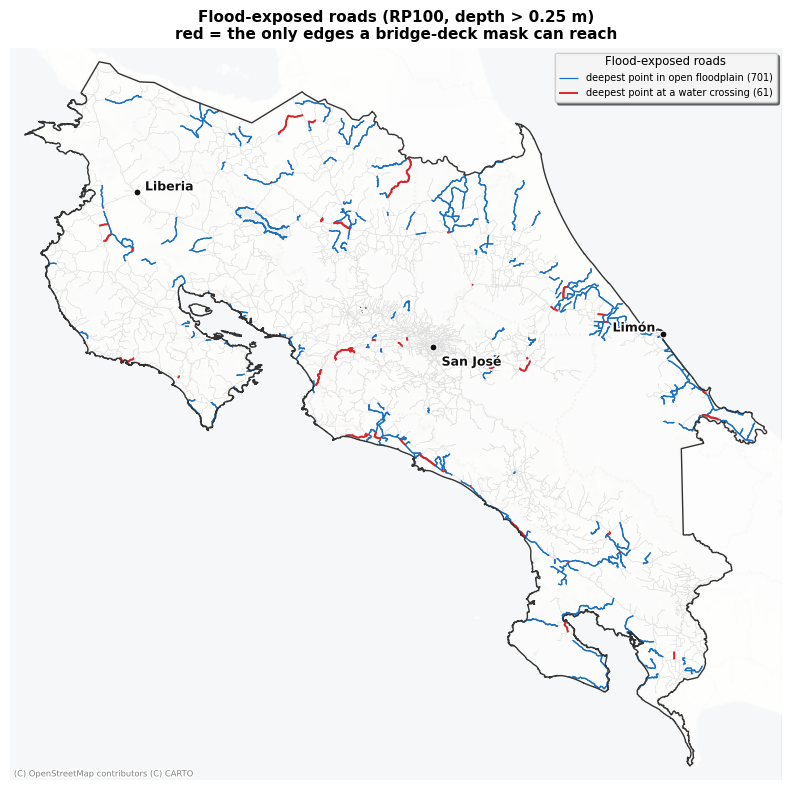

In [25]:
# ---- Sensitivity of flood exposure to the mask radius ---------------------
flood_grid = rasters["flood"]
total_km = roads["road_length"].sum()

rows_sens = []
sample_unmasked = None
for radius in sorted({0.0, 25.0, BRIDGE_MASK_M, 100.0, 200.0}):
    sample = sample_raster_to_roads(
        roads_deg, flood_grid,
        mask_xy=bridge_mask_xy if radius > 0 else None,
        mask_radius_m=radius,
    )
    if radius == 0.0:
        sample_unmasked = sample
    depth = np.where(np.isnan(sample.max()), 0.0, sample.max())
    exposed = depth > FLOOD_DEPTH_THRESHOLD
    rows_sens.append({
        "mask_m": radius,
        "edges": int(exposed.sum()),
        "length_km": roads.loc[exposed, "road_length"].sum(),
        "length_share": roads.loc[exposed, "road_length"].sum() / total_km,
        "max_depth_m": float(depth.max()),
    })

sens = pd.DataFrame(rows_sens)
print(sens.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))
print(f"\nin use: {BRIDGE_MASK_M:.0f} m  -- note how little the radius changes the answer")

# ---- Where does the deepest point actually sit? ---------------------------
# The diagnostic that matters is not "does the edge pass near a bridge" (almost every
# river crossing does) but "is the cell driving `max` at the bridge".
#
# This MUST use the unmasked sample. The masked one is NaN at every crossing by
# construction, so its argmax can never land on one and the answer would be 0 % by
# definition rather than by measurement.
_, _, vx, vy, _ = _densify(roads_deg, flood_grid.resolution / 2)
near_crossing = np.zeros(len(sample_unmasked.value), dtype=bool)
_near = [
    np.asarray(n, dtype=int)
    for n in cKDTree(np.column_stack([vx, vy])).query_ball_point(
        bridge_mask_xy, r=BRIDGE_MASK_M
    )
    if len(n)
]
if _near:
    near_crossing[np.unique(np.concatenate(_near))] = True

finite = np.isfinite(sample_unmasked.value)
frame = pd.DataFrame(
    {
        "road": sample_unmasked.road[finite],
        "v": sample_unmasked.value[finite],
        "near": near_crossing[finite],
    }
)
argmax_rows = frame.loc[frame.groupby("road")["v"].idxmax()]

depth_unmasked = np.where(np.isnan(sample_unmasked.max()), 0.0, sample_unmasked.max())
exposed_unmasked = depth_unmasked > FLOOD_DEPTH_THRESHOLD
at_crossing = argmax_rows[argmax_rows["road"].isin(np.where(exposed_unmasked)[0])]

roads["max_at_crossing"] = False
roads.loc[at_crossing.loc[at_crossing["near"], "road"].to_numpy(), "max_at_crossing"] = True
extra_cols.append("max_at_crossing")

print(
    f"\nbefore masking, {int(exposed_unmasked.sum()):,} edges are flood-exposed; the DEEPEST "
    f"point is within {BRIDGE_MASK_M:.0f} m of a water crossing on "
    f"{int(at_crossing['near'].sum()):,} of them ({at_crossing['near'].mean():.1%})"
)
print("-> the RP100 over-estimate is floodplain, not bridge deck (see the markdown above)")

# ---- Map: flood exposure, split by what the mask can reach -----------------
fig, ax = plt.subplots(figsize=(9, 8))
roads_deg.plot(ax=ax, color="#dddddd", linewidth=0.25, zorder=2)

open_plain = exposed_unmasked & ~roads["max_at_crossing"].to_numpy()
at_bridge = exposed_unmasked & roads["max_at_crossing"].to_numpy()
for mask, colour, width, zorder, label in [
    (open_plain, "#1a6fbf", 0.9, 3, f"deepest point in open floodplain ({int(open_plain.sum()):,})"),
    (at_bridge, "#d62728", 1.4, 4, f"deepest point at a water crossing ({int(at_bridge.sum()):,})"),
]:
    if mask.any():                       # geopandas cannot plot an empty frame
        roads_deg[mask].plot(ax=ax, color=colour, linewidth=width, zorder=zorder, label=label)

style_cr_map(ax, RASTER_EPSG, legend_handles=ax.get_legend_handles_labels()[0],
             legend_title="Flood-exposed roads")
ax.set_title(
    f"Flood-exposed roads (RP100, depth > {FLOOD_DEPTH_THRESHOLD} m)\n"
    f"red = the only edges a bridge-deck mask can reach",
    fontsize=11, fontweight="bold",
)
plt.tight_layout()
save_fig(fig, "flood_exposure_correction.png")
plt.show()


In [26]:
# ---- Class breakdown per hazard ------------------------------------------
for layer in HAZARDS:
    share = (
        roads.groupby(layer.class_col, observed=False)["road_length"].sum()
        / roads["road_length"].sum()
    )
    print(f"\n{layer.label}  — share of network length")
    for name, value in share.items():
        print(f"  {str(name):<14} {value:6.1%}")



Fluvial flood depth (RP100)  — share of network length
  No flooding     83.5%
  < 0.5 m          0.3%
  0.5 - 1 m        4.2%
  1 - 2 m          1.6%
  > 2 m           10.3%

Landslide susceptibility (NASA LHASA)  — share of network length
  None             0.0%
  Very low         4.4%
  Low             23.7%
  Moderate        17.8%
  High            16.9%
  Very high       37.1%

Precipitation anomaly 2025 vs 2000-2024  — share of network length
  Much drier       0.0%
  Drier            1.7%
  Near normal     17.1%
  Wetter          14.3%
  Much wetter     66.6%

Rx1month, 20-year return level  — share of network length
  Low             24.1%
  Moderate        34.1%
  High            28.9%
  Very high       12.5%


## 8. Hazard maps


saved  figures/hazard_raster_flood.png


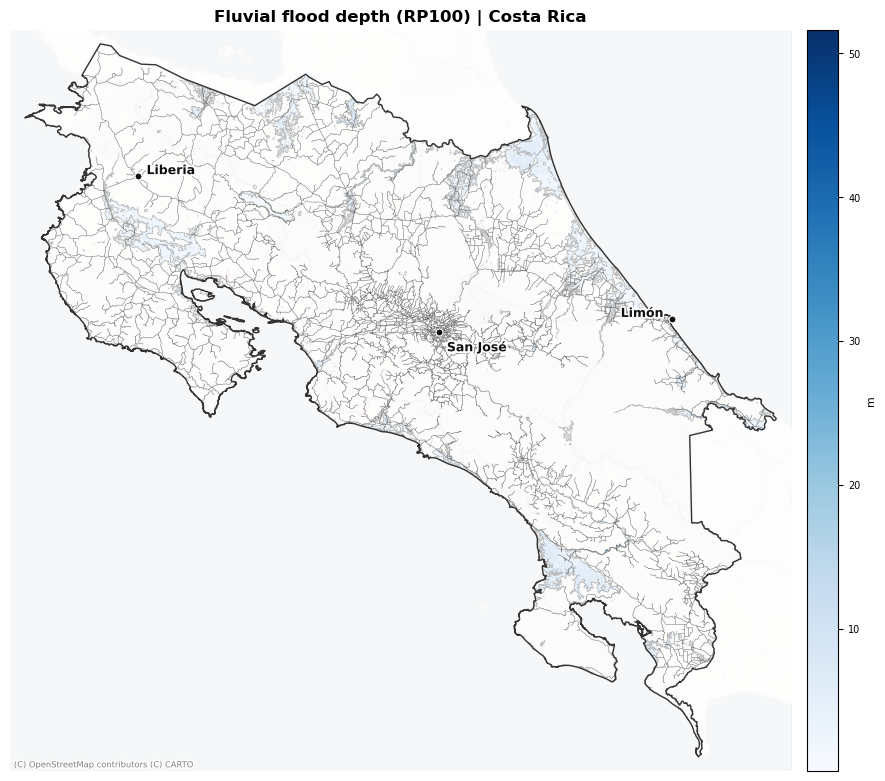

saved  figures/hazard_raster_landslide.png


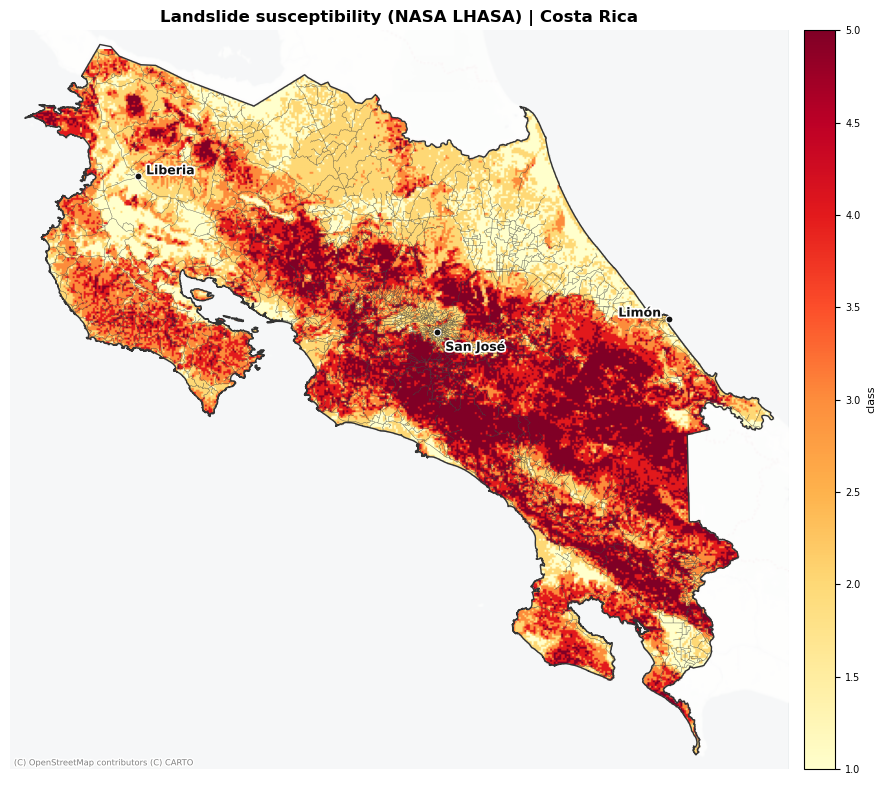

saved  figures/hazard_raster_precip_anomaly.png


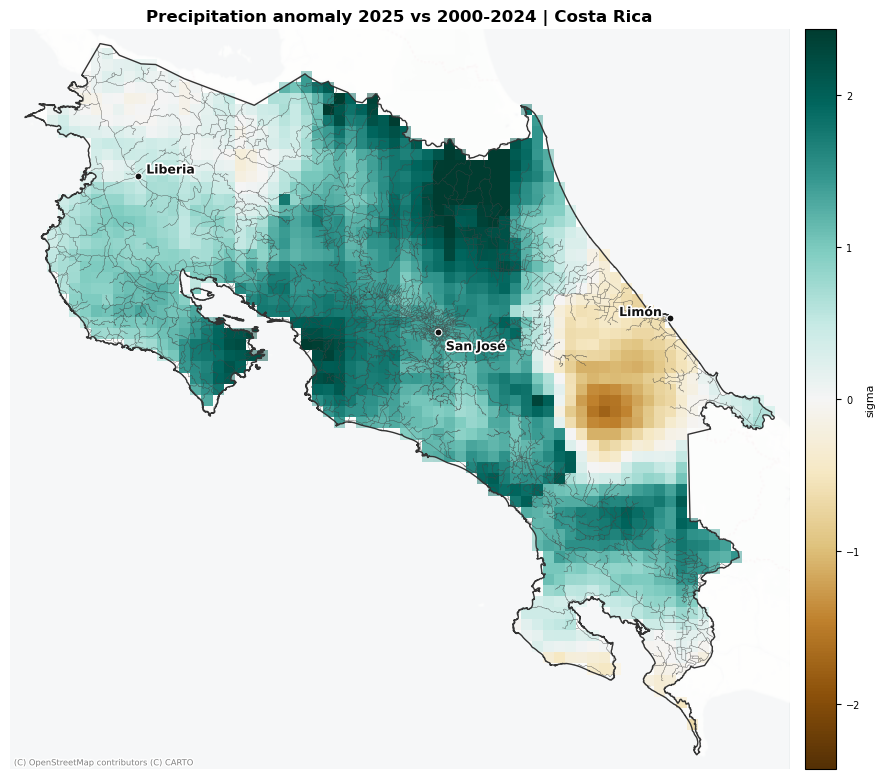

saved  figures/hazard_raster_precip_rx1month.png


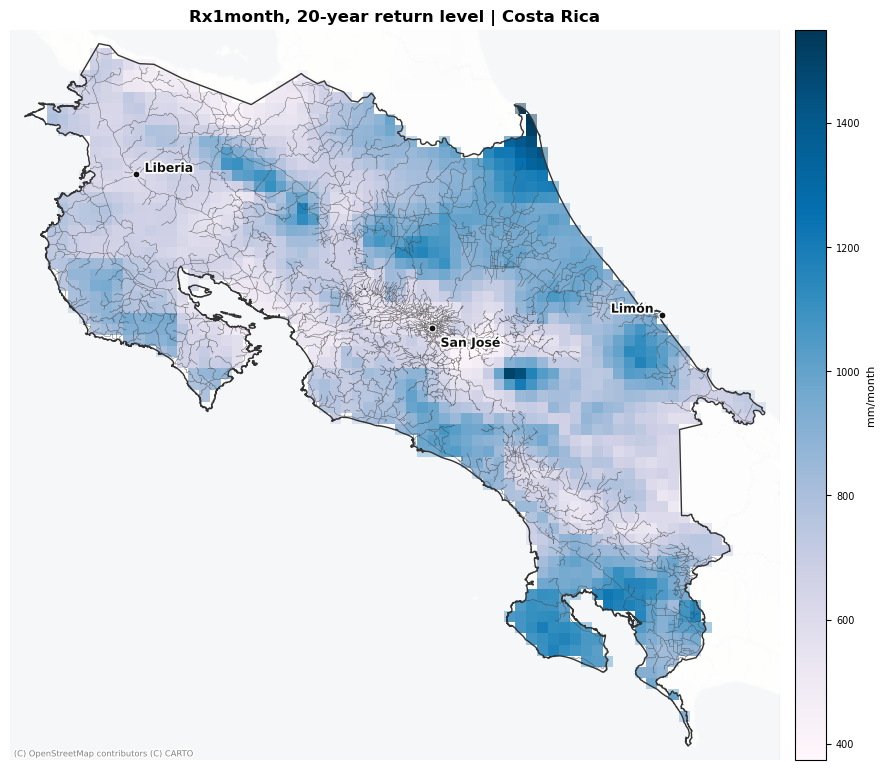

In [27]:
def plot_hazard_raster(layer: HazardLayer, raster: Raster) -> None:
    """Map the hazard grid with the Costa Rica outline and the network on top."""
    fig, ax = plt.subplots(figsize=(9, 8))

    finite = raster.data[np.isfinite(raster.data)]
    if finite.size == 0:
        print(f"skipped {layer.key}: no finite cells to map")
        plt.close(fig)
        return
    if layer.diverging:
        vlim = np.percentile(np.abs(finite), 98)
        norm = TwoSlopeNorm(vmin=-vlim, vcenter=0, vmax=vlim)
    else:
        norm = None

    im = ax.imshow(raster.data, extent=raster.extent, origin="upper",
                   cmap=layer.cmap, norm=norm)
    roads_deg.plot(ax=ax, color="#444444", linewidth=0.25, alpha=0.6, zorder=4)

    style_cr_map(ax, RASTER_EPSG)
    ax.set_title(f"{layer.label} | Costa Rica", fontsize=12, fontweight="bold")

    cax = make_axes_locatable(ax).append_axes("right", size="4%", pad=0.1)
    cb = plt.colorbar(im, cax=cax)
    cb.set_label(layer.units, fontsize=8)
    cb.ax.tick_params(labelsize=7)

    plt.tight_layout()
    save_fig(fig, f"hazard_raster_{layer.key}.png")
    plt.show()


for layer in HAZARDS:
    plot_hazard_raster(layer, rasters[layer.key])


saved  figures/hazard_raster_flood.png


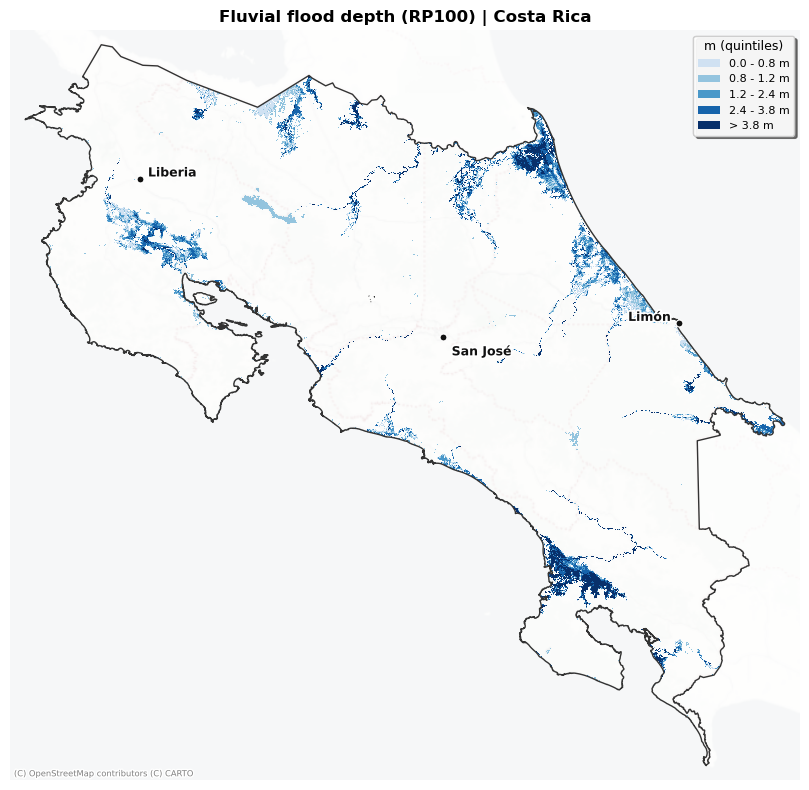

saved  figures/hazard_raster_landslide.png


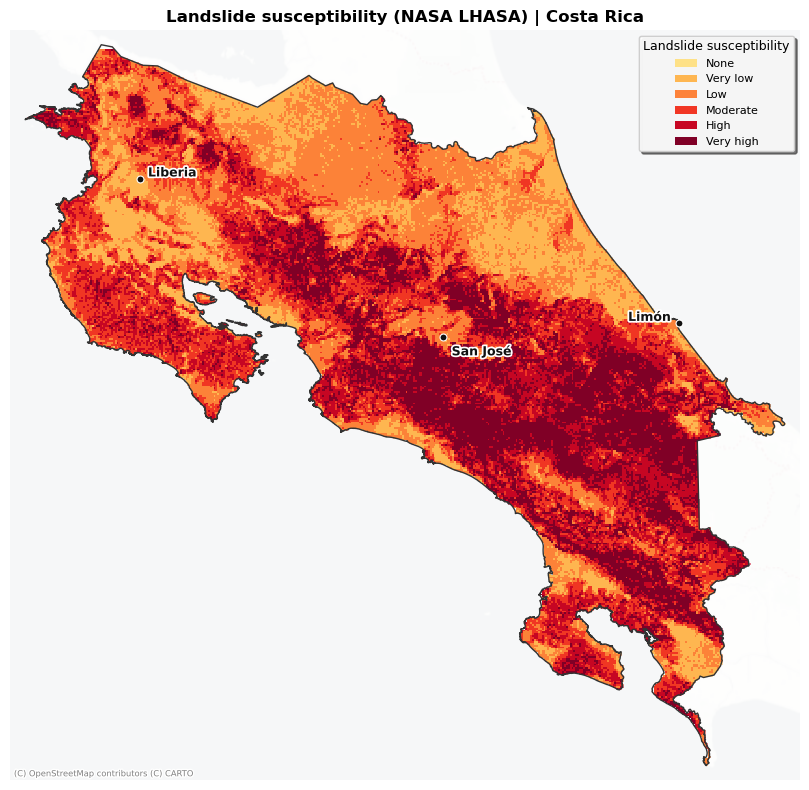

saved  figures/hazard_raster_precip_anomaly.png


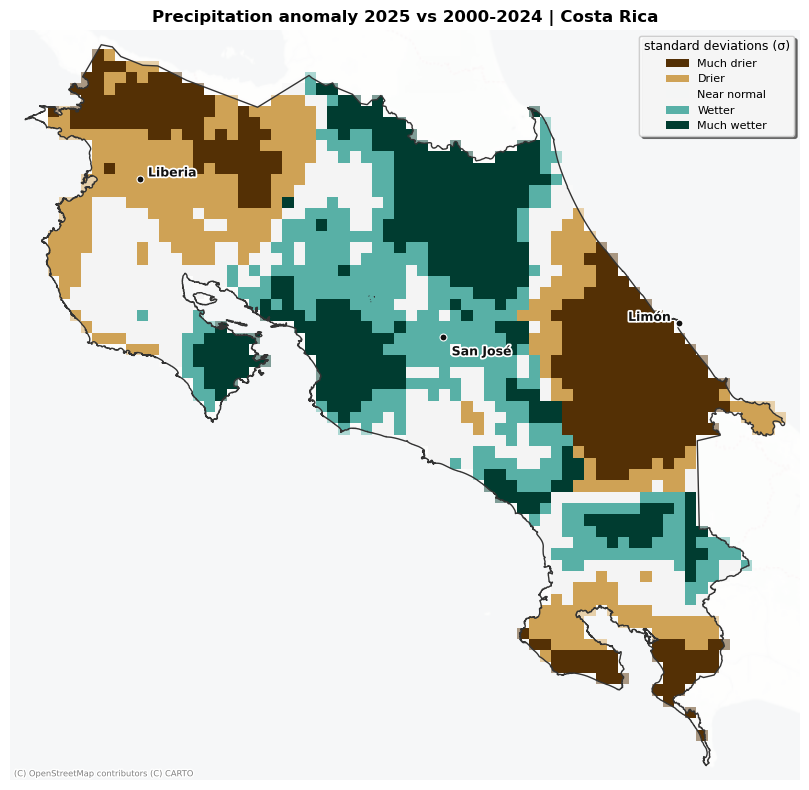

saved  figures/hazard_raster_precip_rx1month.png


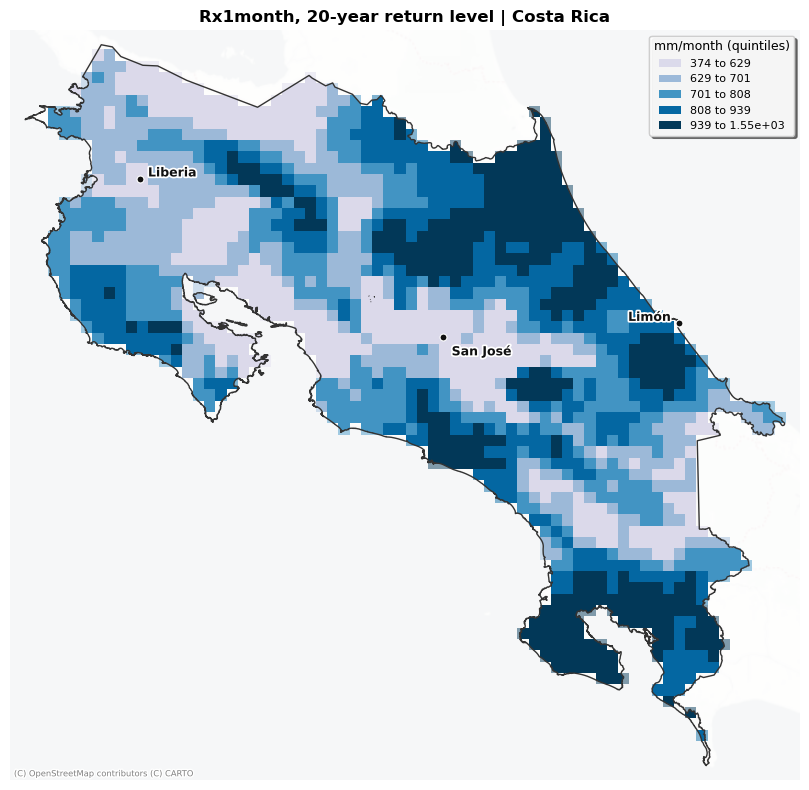

In [36]:
MANUAL_BIN_LABELS = {
    "flood": ["0.0 - 0.8 m", "0.8 - 1.2 m", "1.2 - 2.4 m", "2.4 - 3.8 m", "> 3.8 m"],
    "precip_anomaly": ["Much drier", "Drier", "Near normal", "Wetter", "Much wetter"],
    #"precip_rx1month": ["Lowest", "Low", "Moderate", "High", "Highest"],
}
def plot_hazard_raster(layer: HazardLayer, raster: Raster) -> None:
    """Map the hazard grid in classes with the Costa Rica outline (no network overlay)."""
    fig, ax = plt.subplots(figsize=(9, 8))

    finite = raster.data[np.isfinite(raster.data)]
    if finite.size == 0:
        print(f"skipped {layer.key}: no finite cells to map")
        plt.close(fig)
        return

    if layer.key == "landslide":
        # Discrete 0-5 grid: one bin per LHASA class, centred on the integer values.
        edges = np.arange(-0.5, len(layer.class_labels), 1.0)
        labels = layer.class_labels
        legend_title = "Landslide susceptibility"
    else:
        # Quintiles of the finite cells; tied edges are merged, so fewer than five
        # bins are possible.
        edges = np.unique(np.quantile(finite, np.linspace(0, 1, 6)))
        if len(edges) < 2:
            print(f"skipped {layer.key}: all cells share one value")
            plt.close(fig)
            return
        labels = MANUAL_BIN_LABELS.get(layer.key)
        if labels is None or len(labels) != len(edges) - 1:
            labels = [f"{edges[i]:.3g} to {edges[i + 1]:.3g}" for i in range(len(edges) - 1)]
        legend_title = (
            "standard deviations (σ)" if layer.key == "precip_anomaly" else f"{layer.units} (quintiles)"
        )

    n_bins = len(edges) - 1
    lo = 0.0 if layer.diverging else 0.2
    bin_colors = plt.get_cmap(layer.cmap)(np.linspace(lo, 1, n_bins))
    norm = BoundaryNorm(edges, ncolors=n_bins)

    ax.imshow(raster.data, extent=raster.extent, origin="upper",
              cmap=ListedColormap(bin_colors), norm=norm, interpolation="nearest")

    handles = [Patch(facecolor=bin_colors[i], edgecolor="none", label=labels[i])
               for i in range(n_bins)]
    style_cr_map(ax, RASTER_EPSG, legend_handles=handles, legend_title=legend_title,
                 legend_kw=dict(fontsize=8, title_fontsize=9))
    ax.set_title(f"{layer.label} | Costa Rica", fontsize=12, fontweight="bold")

    plt.tight_layout()
    save_fig(fig, f"hazard_raster_{layer.key}.png")
    plt.show()


for layer in HAZARDS:
    plot_hazard_raster(layer, rasters[layer.key])

saved  figures/hazard_roads_flood.png


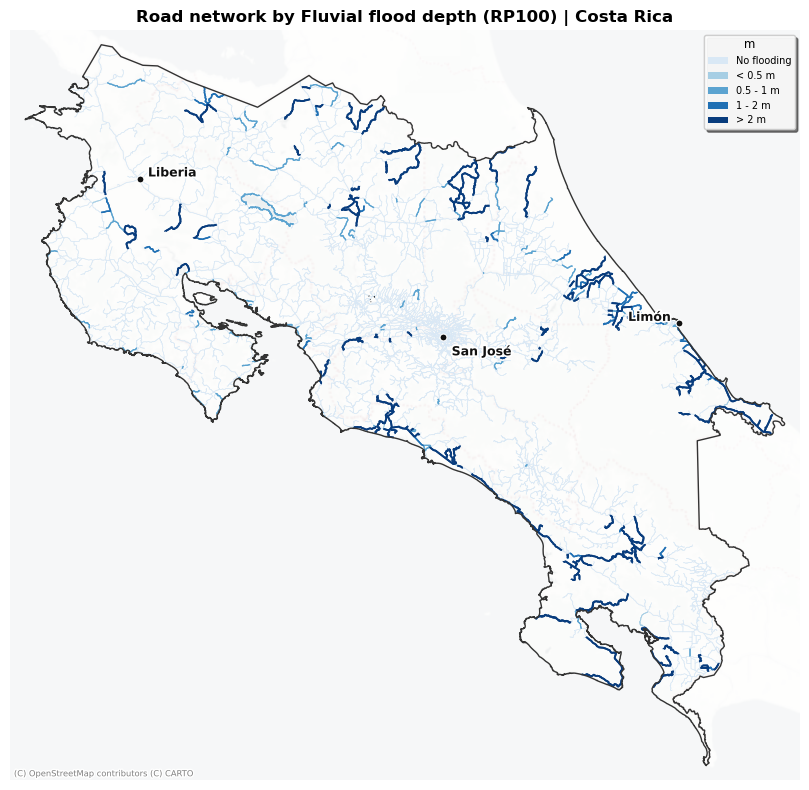

saved  figures/hazard_roads_landslide.png


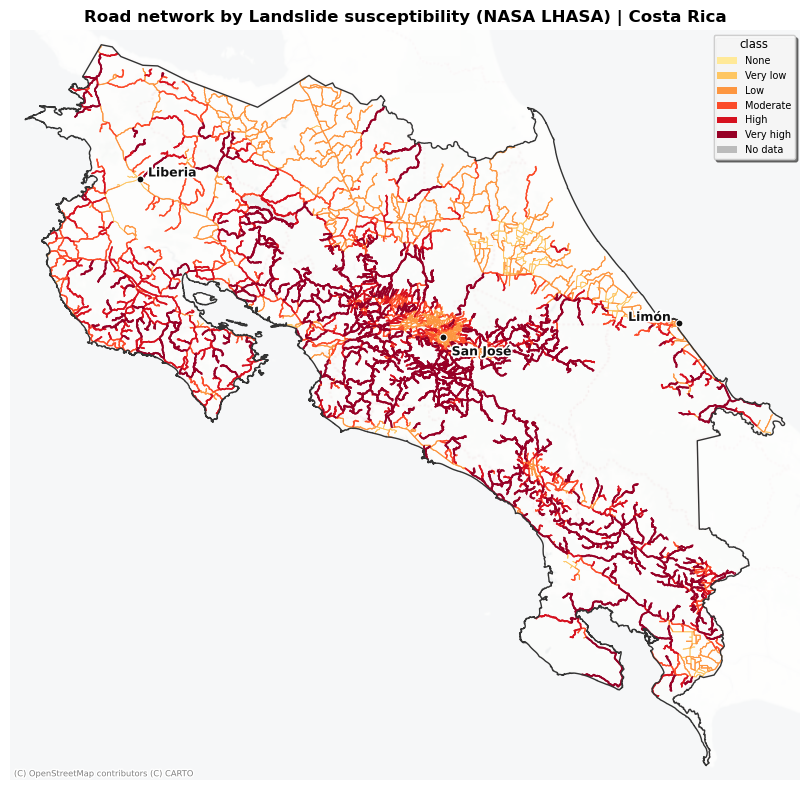

saved  figures/hazard_roads_precip_anomaly.png


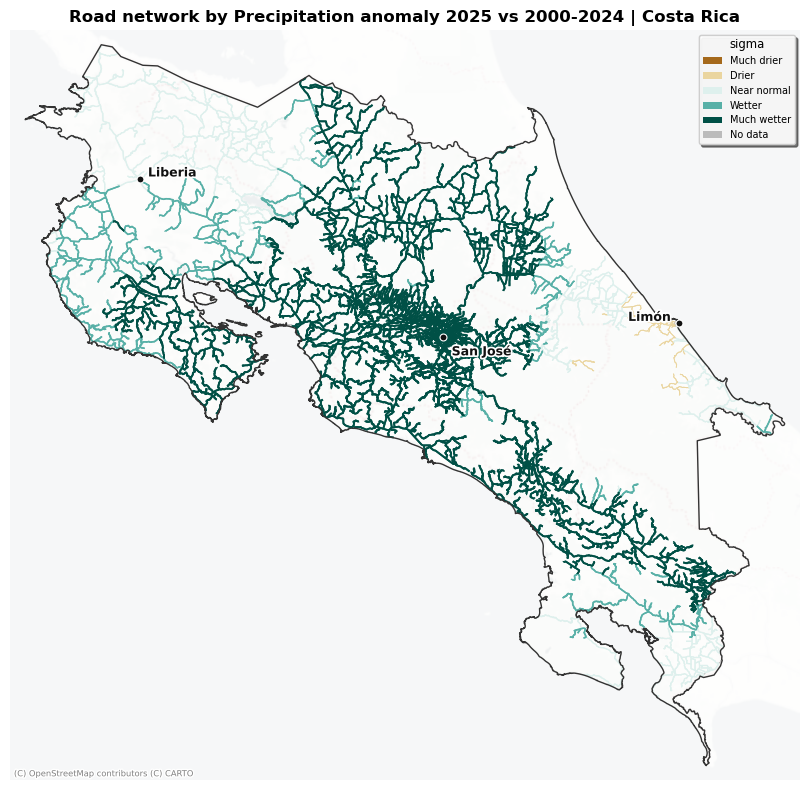

saved  figures/hazard_roads_precip_rx1month.png


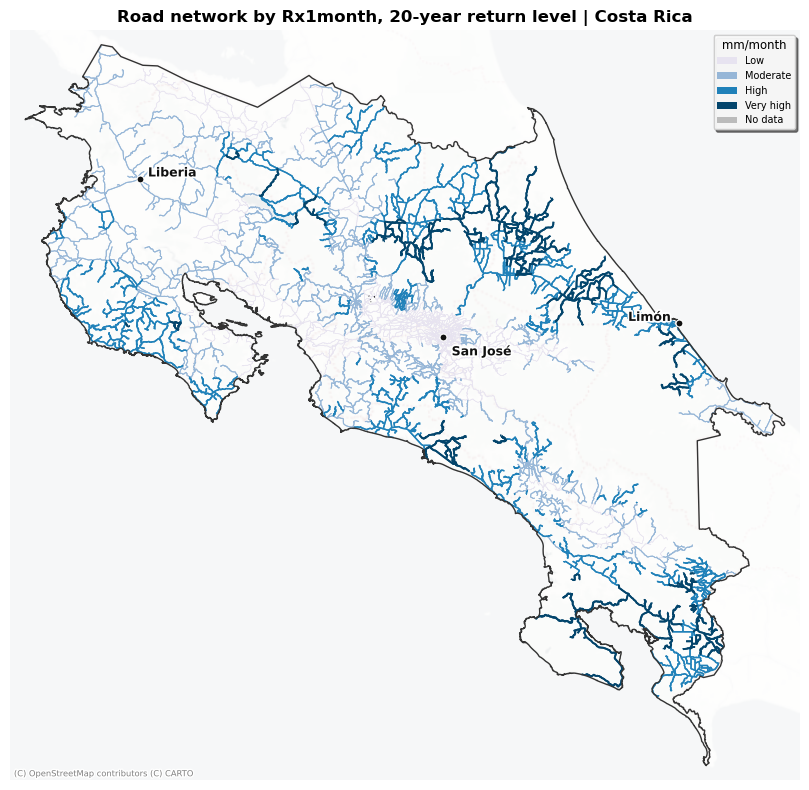

In [28]:
def plot_hazard_roads(layer: HazardLayer) -> None:
    """Map the network coloured by hazard class."""
    labels = list(layer.class_labels)
    colors = plt.get_cmap(layer.cmap)(np.linspace(0.15, 0.95, len(labels)))
    lookup = dict(zip(labels, colors))

    fig, ax = plt.subplots(figsize=(9, 8))

    plotted = roads_deg.assign(**{layer.class_col: roads[layer.class_col].to_numpy()})
    unclassified = plotted[plotted[layer.class_col].isna()]
    if len(unclassified):
        unclassified.plot(ax=ax, color="#bbbbbb", linewidth=0.4, zorder=2)

    for name in labels:
        subset = plotted[plotted[layer.class_col] == name]
        if subset.empty:
            continue
        # Thicker lines for the more severe classes so they stay visible.
        width = 0.4 + 0.9 * (labels.index(name) / max(len(labels) - 1, 1))
        subset.plot(ax=ax, color=lookup[name], linewidth=width,
                    zorder=3 + labels.index(name))

    handles = [Patch(facecolor=lookup[n], label=n) for n in labels]
    if len(unclassified):
        handles.append(Patch(facecolor="#bbbbbb", label="No data"))
    style_cr_map(ax, RASTER_EPSG, legend_handles=handles, legend_title=layer.units)
    ax.set_title(f"Road network by {layer.label} | Costa Rica",
                 fontsize=12, fontweight="bold")
    plt.tight_layout()
    save_fig(fig, f"hazard_roads_{layer.key}.png")
    plt.show()


for layer in HAZARDS:
    plot_hazard_roads(layer)


saved  figures/hazard_exposure_summary.png


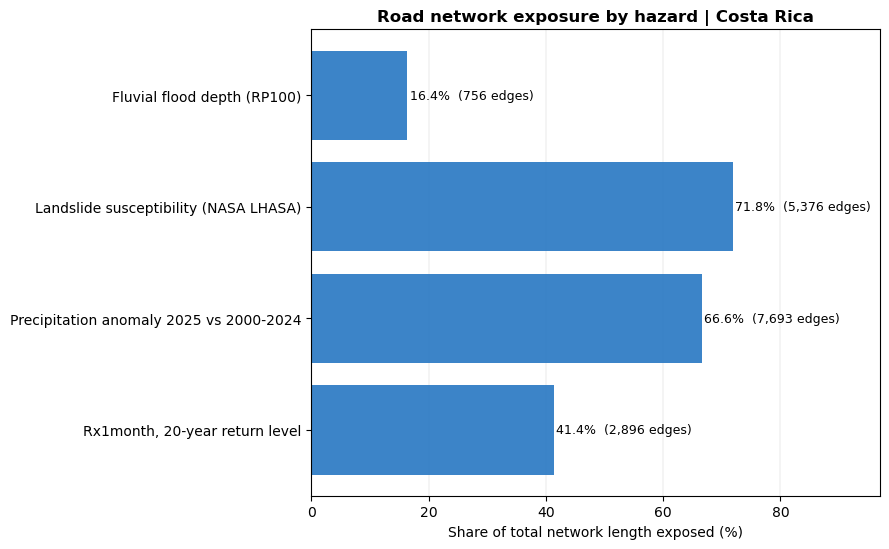

,hazard,edges_exposed,length_share
0,Fluvial flood depth (RP100),756,16.4%
1,Landslide susceptibility (NASA LHASA),5376,71.8%
2,Precipitation anomaly 2025 vs 2000-2024,7693,66.6%
3,"Rx1month, 20-year return level",2896,41.4%


In [29]:
# ---- Exposure summary across all hazards ---------------------------------
total_length = roads["road_length"].sum()
summary = pd.DataFrame(
    [
        {
            "hazard": layer.label,
            "edges_exposed": int(layer.exposed_if(roads[layer.value_col].to_numpy()).sum()),
            "length_share": roads.loc[
                layer.exposed_if(roads[layer.value_col].to_numpy()), "road_length"
            ].sum() / total_length,
        }
        for layer in HAZARDS
    ]
)

fig, ax = plt.subplots(figsize=(9, 0.9 * len(summary) + 2))
bars = ax.barh(summary["hazard"], summary["length_share"] * 100, color="#1a6fbf", alpha=0.85)
for bar, (_, row) in zip(bars, summary.iterrows()):
    ax.text(bar.get_width() + 0.4, bar.get_y() + bar.get_height() / 2,
            f"{row['length_share']:.1%}  ({row['edges_exposed']:,} edges)",
            va="center", fontsize=9)
ax.set_xlabel("Share of total network length exposed (%)", fontsize=10)
ax.set_xlim(0, max(summary["length_share"].max() * 100 * 1.35, 5))
ax.invert_yaxis()
ax.set_title("Road network exposure by hazard | Costa Rica", fontsize=12, fontweight="bold")
ax.grid(axis="x", linewidth=0.3, color="#cccccc")
ax.set_axisbelow(True)
plt.tight_layout()
save_fig(fig, "hazard_exposure_summary.png")
plt.show()

summary.style.format({"length_share": "{:.1%}"})


## 9. Save the hazard-exposure network


In [30]:
# Keep the routing identifiers plus every hazard column; drop the bulky 1b diagnostics.
id_cols = [
    "id", "physical_edge_id", "from_id", "to_id", "ID_TRAMO", "ID_RUTA", "NOMBRE",
    "CLASE", "ADMIN", "road_length", "speed", "fft", "total_aadt", "aadt_imputed",
]
keep = (
    [c for c in id_cols if c in roads.columns]
    + hazard_cols
    + [c for c in extra_cols if c in roads.columns]
    + ["geometry"]
)

hazard_network = roads[keep].to_crs(WORKING_EPSG)

# Categorical dtypes do not survive the GPKG writer; store the class names as text.
for layer in HAZARDS:
    hazard_network[layer.class_col] = hazard_network[layer.class_col].astype("string")

hazard_network.to_file(hazard_gpkg, layer="main_network_hazard_exposure", driver="GPKG")

print(f"saved  {hazard_gpkg.relative_to(BASE_DIR)}")
print(f"       {len(hazard_network):,} edges x {len(keep)} columns  ({hazard_network.crs})")
print(f"       hazard columns : {', '.join(hazard_cols)}")
print(f"       extra columns  : {', '.join(c for c in extra_cols if c in roads.columns)}")
print()
print("Regime flags carried in the output (plan issue I1c):")
print(f"  flood_correction_applied = {FLOOD_CORRECTION_APPLIED}  "
      f"(DEM {'found' if dem_path else 'absent'}, road Z {'present' if roads_have_z else 'absent'})")
print(f"  bridge mask radius       = {BRIDGE_MASK_M:.0f} m")
print(f"  flood depth threshold    = {FLOOD_DEPTH_THRESHOLD} m")
print(f"  implausible-depth ceiling = {FLOOD_DEPTH_CEILING} m (flag only, never clipped)")

saved  intermediate_results/gpkg/hazard_exposure/main_network_hazard_exposure.gpkg
       9,764 edges x 41 columns  (EPSG:8908)
       hazard columns : flood_value, flood_class, landslide_value, landslide_class, precip_anomaly_value, precip_anomaly_class, precip_rx1month_value, precip_rx1month_class
       extra columns  : n_water_crossings, has_temporary_structure, flood_share_gt0p25, flood_depth_implausible, flood_depth_rp10, flood_depth_rp20, flood_depth_rp50, flood_depth_rp75, flood_depth_rp100, flood_depth_rp200, flood_depth_rp500, flood_min_rp, flood_rp_censored, flood_aep, road_freeboard_m, flood_depth_dem_corrected, flood_correction_applied, max_at_crossing

Regime flags carried in the output (plan issue I1c):
  flood_correction_applied = False  (DEM absent, road Z absent)
  bridge mask radius       = 50 m
  flood depth threshold    = 0.25 m
  implausible-depth ceiling = 6.0 m (flag only, never clipped)
